# Text Classification and Analysis
* Read in a collection of documents
* Analysis of the event and strategy columns
* Analysis of the media corpus characteristics (language, media type, etc)
* Load the Spacy language model
* Do some text processing and lemmatize english news content using the Spcy lemmatizer
* Use TFIDF to fit and tranform the vectorized texts
* Implement NMF for topic modelling
* Implement t-SNE to visualize the topics
* Implement geoparsing
* Implement BertTopic (optional)
* Keyword tagging

## Perform imports and load the dataset


In [ ]:
%%capture
!pip install "datamapplot==0.3.0"
!pip install kaleido==0.2.1

In [ ]:
#pip install kaleido -q

In [ ]:
#!pip install "datamapplot==0.3.0" # Ensure installation for the current session
import kaleido
import datamapplot
print("DataMapPlot:", datamapplot.__version__)

DataMapPlot: 0.3.0


In [ ]:
%%capture
!pip install sentence-transformers #>=2.2.0
!pip install plotly
!pip install wordcloud
!python -m spacy download en_core_web_lg
!pip install bertopic
!pip install nltk
!pip install gensim
!pip install scikit-learn

In [ ]:
import os
import re
import pandas as pd
import numpy as np
from typing import Tuple
import copy as cp
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
from wordcloud import WordCloud
from sentence_transformers import SentenceTransformer
import torch
from collections import Counter
import warnings
warnings.filterwarnings('ignore')
import nltk
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
import spacy
import plotly.express as px
os.environ["PYDANTIC_V1_ALLOW"] = "true"  # allow v1 compatibility layer
print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [ ]:
%%capture
!python -m spacy validate

In [ ]:
#Import libraries for semantic analysis and other tasks
nlp = spacy.load("en_core_web_lg")

In [ ]:
from warnings import warn
try:
    import datamapplot
    from matplotlib.figure import Figure
except ImportError:
    warn("Data map plotting is unavailable unless datamapplot is installed.")

    # Create a dummy figure type for typing
    class Figure(object):
        pass

## Load the file with the news which have been tagged, selected and translated


In [ ]:
file_path = '/content/drive/MyDrive/deep_learning_7_SV/Blatten_news/'
figure_path = '/content/drive/MyDrive/deep_learning_7_SV/Blatten_news/Figures/'

In [ ]:
### TODO Add your file path ###
#file_path = '/content/drive/MyDrive/deep_learning_7_SV/Blatten_news/'
#file_name = 'news_predictions_all_relevant_translated_lemma_20251201.csv'
#file_name = 'my_news_translated_en_LLM_final_ver20260105.csv'
file_name = 'Blatten_DataExtraction_GivenLabels_20260313.csv'
df_orig = pd.read_csv(file_path + file_name)
len(df_orig)

2094

In [ ]:
# Remove duplicated
df_orig= df_orig.drop_duplicates(subset="id", keep="first")   # or keep="last"

In [ ]:
len(df_orig)

2094

In [ ]:
## Remove further duplicates using threshold semantic similarity. High thresholds imply almost same text.

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

model = SentenceTransformer("sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2")
texts = df_orig["content_en"].fillna("").tolist()

emb = model.encode(texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True)

# cosine sim matrix (OK for a few thousand docs; for 10k+ use FAISS)
S = cosine_similarity(emb)

thr = 0.95  # tune: 0.88–0.95 typical
keep = []
dropped = set()

for i in range(len(texts)):
    if i in dropped:
        continue
    keep.append(i)

    # drop near-semantic duplicates of i
    dup_idx = np.where(S[i] >= thr)[0]
    for j in dup_idx:
        if j > i and j not in dropped:  # Only look forward to avoid order bias
            dropped.add(int(j))

unique_df = df_orig.iloc[keep].copy()

In [ ]:
# After deduplication, verify:
print(f"Kept: {len(keep)}, Dropped: {len(dropped)}")
print(f"Removal rate: {len(dropped)/len(texts)*100:.1f}%")

# Spot-check some dropped pairs
sample_dropped = list(dropped)[:5]
for idx in sample_dropped:
    # Find what it was similar to
    kept_similar = [i for i in keep if S[idx, i] >= thr]
    if kept_similar:
        print(f"\n--- Dropped article {idx} (similar to {kept_similar[0]}) ---")
        print(f"Similarity: {S[idx, kept_similar[0]]:.3f}")
        print(f"Kept: {texts[kept_similar[0]][:400]}...")
        print(f"Drop: {texts[idx][:400]}...")

Kept: 2052, Dropped: 42
Removal rate: 2.0%

--- Dropped article 1155 (similar to 957) ---
Similarity: 0.960
Kept: The debris cone of the mountain collapse in Blatten VS is, according to the chief of the Valais office for natural hazards, locally over meters high. Swiss insurer Risse or larger collapses of the debris pile have not been detected so far, as Raphaël Mayoraz told the media. But that could change as soon as the ice starts to melt, Mayoraz said in an interview with the newspapers «Walliser Bote», «L...
Drop: The debris cone of the mountain collapse in Blatten VS is, according to the head of the Valais office for natural hazards, locally over metres high. Cracks or larger collapses of the debris pile have not been detected so far, as Raphaël Mayoraz told the media. But that could change as soon as the ice begins to melt, Mayoraz said in an interview with the newspapers «Walliser Bote», «Le Nouvelliste»...

--- Dropped article 1800 (similar to 1147) ---
Similarity: 0.979
Kept: 

In [ ]:
unique_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 2052 entries, 0 to 2093
Data columns (total 42 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Unnamed: 0               2052 non-null   int64  
 1   id                       2052 non-null   int64  
 2   pubtime                  2052 non-null   object 
 3   medium_code              2052 non-null   object 
 4   medium_name              2052 non-null   object 
 5   rubric                   1360 non-null   object 
 6   regional                 99 non-null     object 
 7   doctype                  2052 non-null   object 
 8   doctype_description      2052 non-null   object 
 9   language                 2052 non-null   object 
 10  char_count               2052 non-null   int64  
 11  dateline                 353 non-null    object 
 12  head                     2052 non-null   object 
 13  subhead                  78 non-null     object 
 14  article_link             1099

In [ ]:
unique_df["event_llm"] = unique_df["event_llm"].str.replace(
    "permafrost melting",
    "permafrost thawing",
    regex=False
)

## Hazards and DRM strategies analysis

In [ ]:
color_continuous_scale = px.colors.sequential.Brwnyl[::][2:]
plt.rcParams['svg.fonttype'] = 'none'
counts_event = unique_df["event_llm"].str.split(";").explode().str.strip().value_counts().to_frame('count')
counts_event.reset_index(inplace=True)
merged_counts = (counts_event.rename(columns={"event_llm": "Hazard"})
             .sort_values("count", ascending=True))
fig = px.bar(
    merged_counts,
    x="count",
    y="Hazard",
    orientation="h",
    color="count",
    color_continuous_scale=color_continuous_scale,
    #text="occurrences",
    title="Number of media articles mentioning each hazard",
    labels={"count": "News count", "Hazard": ""},
)

fig.update_traces(textposition="outside", cliponaxis=False)

fig.update_layout(
    #template="plotly_white",
    title = {"x": .55,"font": dict(size=20)},
    coloraxis_showscale=True,
        coloraxis_colorbar=dict(
        tickfont=dict(size=16)),
    height=800,
    width=1200,
    margin=dict(l=220, r=60, t=80, b=40),
    # horizontal gridlines only:
    xaxis=dict(showgrid=False, zeroline=False, tickfont=dict(size=16)),
    yaxis=dict(showgrid=True, categoryorder="array", categoryarray=merged_counts["Hazard"].tolist(),tickfont=dict(size=20)),
)

fig.show()
fig.update_layout(template='seaborn')
fig.update_xaxes(showgrid=False)

fig.write_image(figure_path+"Event_description_3.svg",scale=3)
fig.write_image(figure_path+"Event_description_3.png",scale=3)

In [ ]:
df_ht= merged_counts.sort_values(by='count', ascending=False)

df_ht["cum_count"] = df_ht["count"].cumsum()
df_ht["cum_pct"] = df_ht["cum_count"] / df_ht["count"].sum()

df_90 = df_ht[df_ht["cum_pct"] <= 0.90]

df_90

,Hazard,count,cum_count,cum_pct
0,landslide,1174,1174,0.282823
1,rockfall,692,1866,0.449530
2,glacier collapse,541,2407,0.579860
3,flood,444,2851,0.686822
4,avalanche,253,3104,0.747772
5,lake formation,228,3332,0.802698
6,debris flow,199,3531,0.850638
7,mudslide,149,3680,0.886533


In [ ]:
color_continuous_scale = px.colors.sequential.Brwnyl[::][2:]
plt.rcParams['svg.fonttype'] = 'none'
counts_event = unique_df["strategy_llm"].str.split(";").explode().str.strip().value_counts().to_frame('count')
counts_event.reset_index(inplace=True)
merged_counts = (counts_event.rename(columns={"strategy_llm": "Strategy"})
             .sort_values("count", ascending=True))
fig = px.bar(
    merged_counts,
    x="count",
    y="Strategy",
    orientation="h",
    color="count",
    color_continuous_scale=color_continuous_scale,
    #text="occurrences",
    title="Number of media article mentoning disaster response measures",
    labels={"count": "News count", "Strategy": ""},
)

fig.update_traces(textposition="outside", cliponaxis=False)

fig.update_layout(
    #template="plotly_white",
    title = {"x": .55,"font": dict(size=20)},
    coloraxis_showscale=True,
        coloraxis_colorbar=dict(
        tickfont=dict(size=16)),
    height=1000,
    width=1200,
    margin=dict(l=220, r=60, t=80, b=40),
    xaxis=dict(showgrid=False, zeroline=False,tickfont=dict(size=20)),
    yaxis=dict(showgrid=True, categoryorder="array", categoryarray=merged_counts["Strategy"].tolist(),tickfont=dict(size=20)),
)
fig.update_layout(template='seaborn')
fig.show()

fig.write_image(figure_path+"Strategy_description_3.svg",scale=3)
fig.write_image(figure_path+"Strategy_description_3.png",scale=3)

In [ ]:
df_keep = unique_df[['id', 'pubtime', 'medium_code', 'doctype', 'medium_name', 'language', 'content_en', 'event_llm', 'strategy_llm', 'narratives']]

In [ ]:
dfh = pd.concat([df_keep, df_keep["event_llm"].str.replace("; ", ";", regex=False).str.get_dummies(sep=';').rename(lambda x: 'Event:' + x, axis=1)], axis = 1)
dfh = pd.concat([dfh, df_keep["strategy_llm"].str.replace("; ", ";", regex=False).str.get_dummies(sep=';').rename(lambda x: 'Solution:' + x, axis=1)], axis = 1)

In [ ]:
climate_impact_cols = dfh.filter(regex='^Event:').columns
solution_type_cols = dfh.filter(regex='^Solution:').columns

# Initialize a DataFrame to store the counts
co_occurrence_counts = pd.DataFrame(index=solution_type_cols, columns=climate_impact_cols, dtype=int)

# Calculate the count of co-occurrences where both columns are 1
for solution_col in solution_type_cols:
    for climate_col in climate_impact_cols:
        # Logical AND between the two binary columns to find where both are 1
        count = (dfh[solution_col].eq(1) & dfh[climate_col].eq(1)).sum()
        co_occurrence_counts.loc[solution_col, climate_col] = count


# Remove the 'Climate Impact:' and 'Solution type:' prefixes for better display in the heatmap
co_occurrence_counts.columns = co_occurrence_counts.columns.str.replace('Event:', '', regex=False)
co_occurrence_counts.index = co_occurrence_counts.index.str.replace('Solution:', '', regex=False)

co_occurrence_counts = co_occurrence_counts.astype(int)

In [ ]:
co_occurrence_counts_select = co_occurrence_counts[['landslide', 'rockfall', 'glacier collapse','flood','avalanche','lake formation','debris flow','mudslide']]

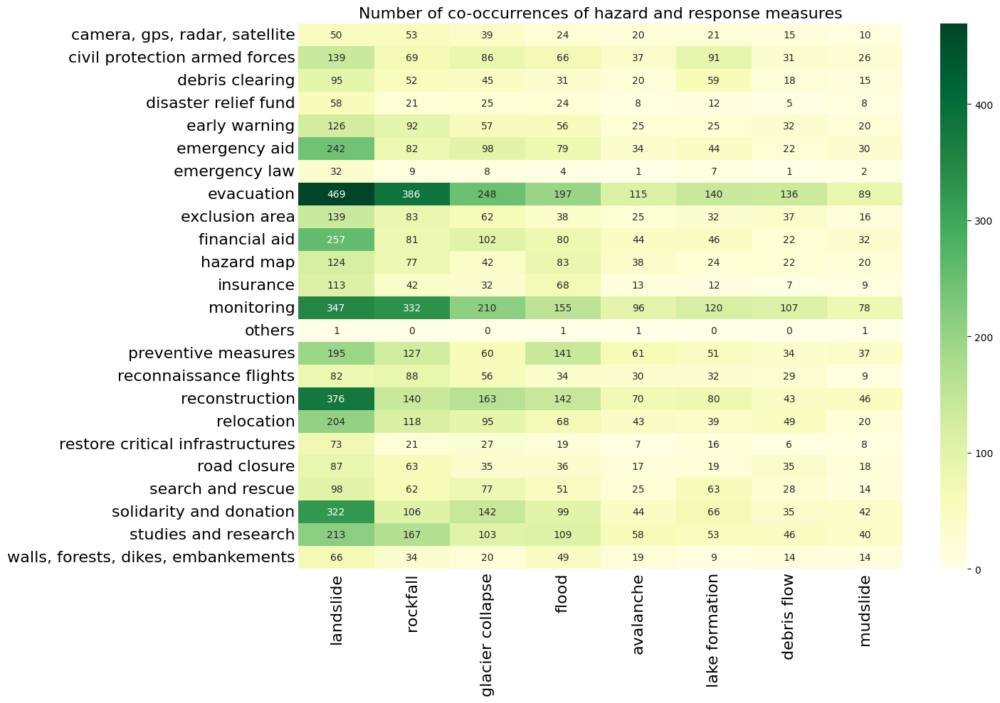

In [ ]:
orig_cmap = plt.cm.YlGn
truncated_cmap = mcolors.LinearSegmentedColormap.from_list(
    "trunc_y lgn",
    orig_cmap(np.linspace(0, 1, 256))
)

fig, ax = plt.subplots(figsize=(15, 10))

sns.heatmap(
    co_occurrence_counts_select, #.drop(columns=["drought", "storm", "temperature"]),
    cmap=truncated_cmap, annot=True, fmt="d",
    ax=ax
)

ax.set_title("Number of co-occurrences of hazard and response measures", fontsize=16)

ax.tick_params(
    axis="both",
    which="both",
    labelsize=16,   # size of tick labels
    length=0        # hide tick marks
)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

#plt.savefig(figure_path+"cooccurance.svg", bbox_inches='tight', transparent = True, facecolor ="w",edgecolor ='w', dpi = 300)
#plt.savefig(figure_path+"cooccurance.png", bbox_inches='tight', transparent = True, facecolor ="w",edgecolor ='w', dpi = 300)

plt.show()

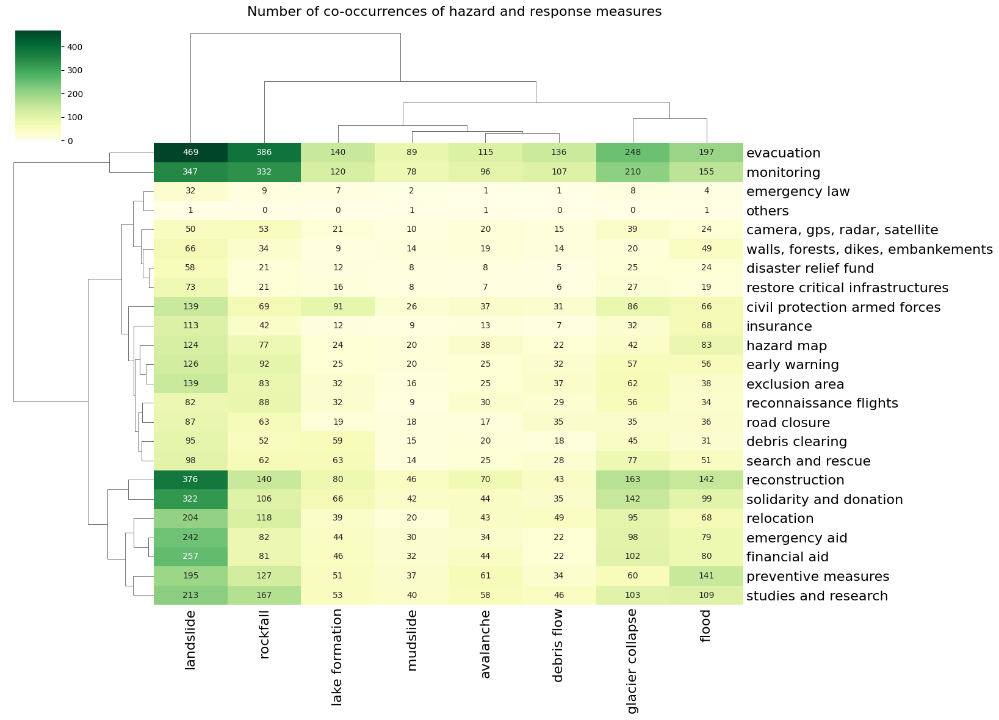

In [ ]:
orig_cmap = plt.cm.YlGn

truncated_cmap = mcolors.LinearSegmentedColormap.from_list(
    "trunc_ylgn",
    orig_cmap(np.linspace(0, 1, 256))
)

g = sns.clustermap(
    co_occurrence_counts_select,
    cmap=truncated_cmap,
    annot=True,
    fmt="d",
    figsize=(15, 10)
)

g.fig.suptitle(
    "Number of co-occurrences of hazard and response measures",
    fontsize=16,
    y=1.02
)

g.ax_heatmap.tick_params(
    axis="both",
    which="both",
    labelsize=16,
    length=0
)

plt.setp(g.ax_heatmap.get_xticklabels(), rotation=90)
plt.setp(g.ax_heatmap.get_yticklabels(), rotation=0)

plt.show()

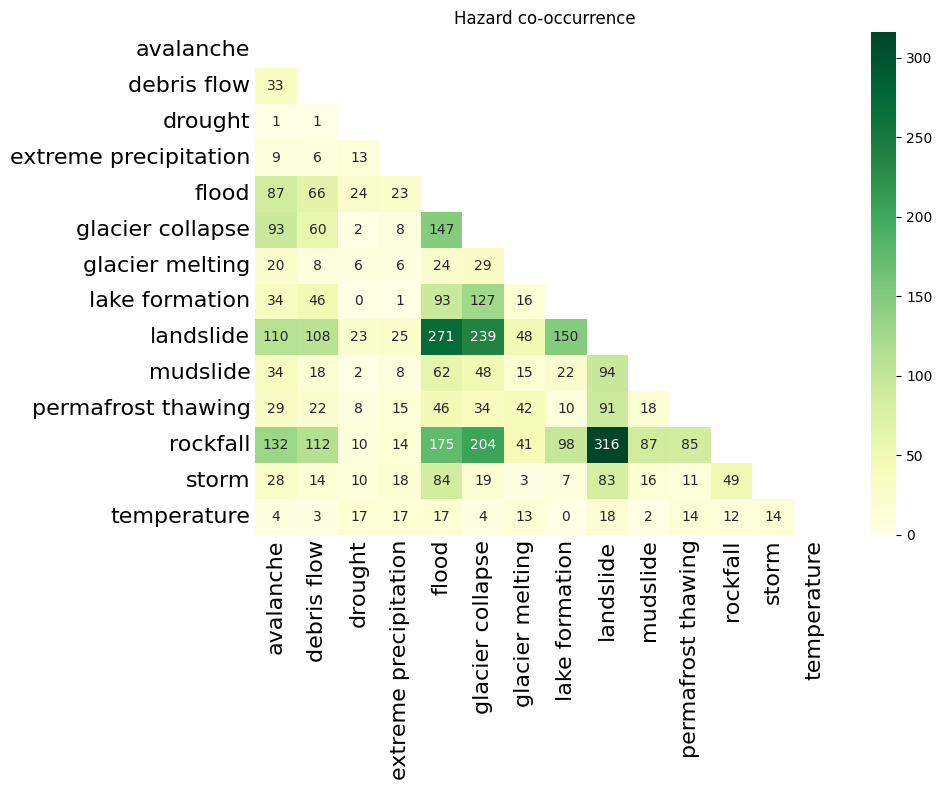

In [ ]:
event_df = dfh.filter(regex=r"^Event:").astype(int)

co_occurrence_events = event_df.T @ event_df

co_occurrence_events.index = co_occurrence_events.index.str.replace("Event:", "", regex=False)
co_occurrence_events.columns = co_occurrence_events.columns.str.replace("Event:", "", regex=False)
mask = np.triu(np.ones_like(co_occurrence_events, dtype=bool))  # mask upper triangle

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(
    co_occurrence_events,
    mask=mask,
    cmap="YlGn",
    annot=True,
    fmt="d",
    ax=ax
)

ax.tick_params(
    axis="both",
    which="both",
    labelsize=16,   # size of tick labels
    length=0        # hide tick marks
)
ax.set_title("Hazard co-occurrence")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(figure_path+"events_cooccurance.svg", bbox_inches='tight', transparent = True, facecolor ="w",edgecolor ='w', dpi = 300)
plt.savefig(figure_path+"events_cooccurance.png", bbox_inches='tight', transparent = True, facecolor ="w",edgecolor ='w', dpi = 300)
plt.show()

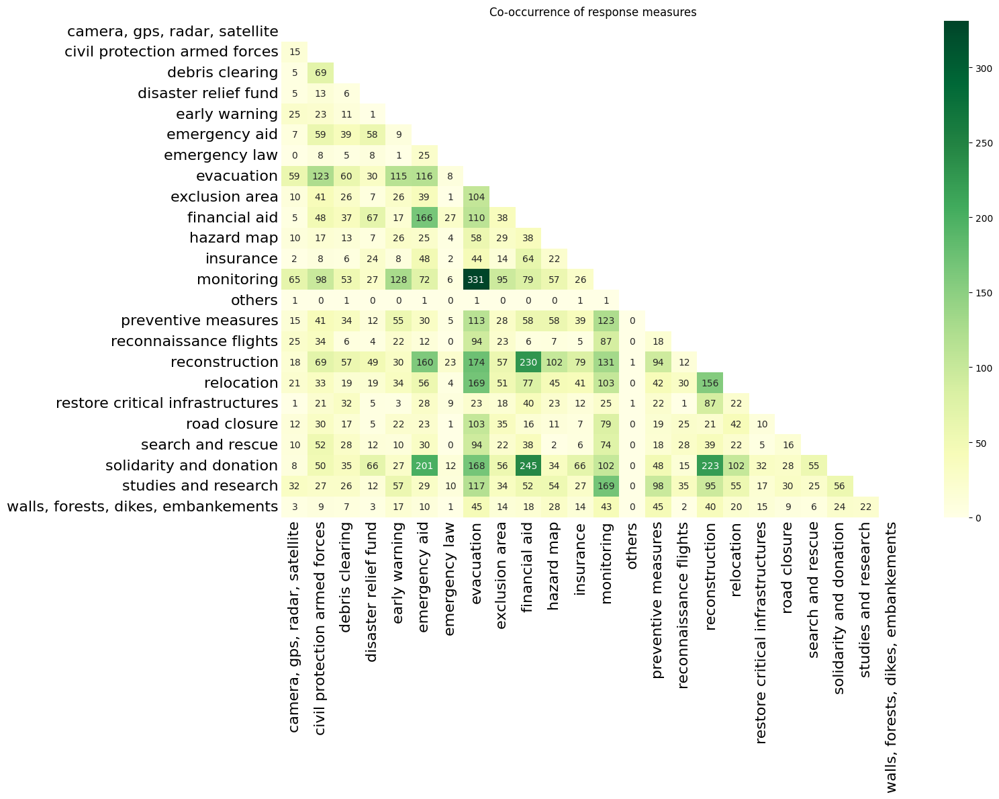

In [ ]:
solution_df = dfh.filter(regex=r"^Solution:").astype(int)

co_occurrence_events = solution_df.T @ solution_df

co_occurrence_events.index = co_occurrence_events.index.str.replace("Solution:", "", regex=False)
co_occurrence_events.columns = co_occurrence_events.columns.str.replace("Solution:", "", regex=False)
mask = np.triu(np.ones_like(co_occurrence_events, dtype=bool))  # mask upper triangle

fig, ax = plt.subplots(figsize=(16, 12))
sns.heatmap(
    co_occurrence_events,
    mask=mask,
    cmap="YlGn",
    annot=True,
    fmt="d",
    ax=ax
)

ax.tick_params(
    axis="both",
    which="both",
    labelsize=16,   # size of tick labels
    length=0        # hide tick marks
)
ax.set_title("Co-occurrence of response measures")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(figure_path+"strategies_cooccurance.svg", bbox_inches='tight', transparent = True, facecolor ="w",edgecolor ='w', dpi = 300)
plt.savefig(figure_path+"strategies_cooccurance.png", bbox_inches='tight', transparent = True, facecolor ="w",edgecolor ='w', dpi = 300)
plt.show()

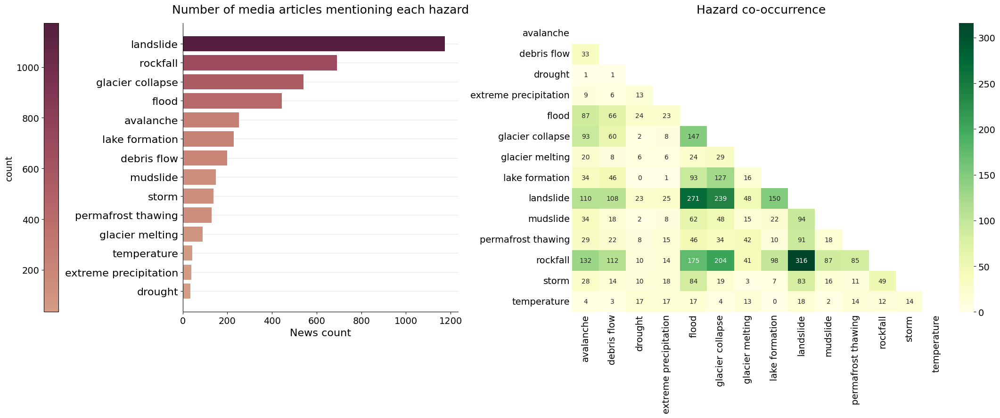

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import plotly.express as px

plt.rcParams['svg.fonttype'] = 'none'

# ============================================================
# TUNABLE PARAMETERS
# ============================================================
FIGSIZE = (22, 9)
WIDTH_RATIOS = [1, 1.1]
TITLE_SIZE = 18
LABEL_SIZE = 16
TICK_SIZE = 14

# ============================================================
# LEFT PANEL DATA — bar chart of hazard counts
# ============================================================
counts_event = (
    unique_df["event_llm"]
    .str.split(";").explode().str.strip()
    .value_counts().to_frame('count')
)
counts_event.reset_index(inplace=True)
merged_counts = (
    counts_event.rename(columns={"event_llm": "Hazard"})
    .sort_values("count", ascending=True)
)

# ============================================================
# RIGHT PANEL DATA — co-occurrence heatmap
# ============================================================
event_df = dfh.filter(regex=r"^Event:").astype(int)
co_occurrence_events = event_df.T @ event_df
co_occurrence_events.index = co_occurrence_events.index.str.replace("Event:", "", regex=False)
co_occurrence_events.columns = co_occurrence_events.columns.str.replace("Event:", "", regex=False)
mask = np.triu(np.ones_like(co_occurrence_events, dtype=bool))

# ============================================================
# COLORMAP — convert Plotly Brwnyl to a matplotlib colormap
# ============================================================
def _plotly_rgb_to_tuple(c):
    if c.startswith("rgb"):
        nums = c[c.index("(")+1:c.index(")")].split(",")
        return tuple(float(n)/255 for n in nums)
    return c

brwnyl_colors = [_plotly_rgb_to_tuple(c) for c in px.colors.sequential.Brwnyl[2:]]
brwnyl_cmap = LinearSegmentedColormap.from_list("Brwnyl", brwnyl_colors)

# ============================================================
# FIGURE
# ============================================================
fig, axes = plt.subplots(
    1, 2,
    figsize=FIGSIZE,
    gridspec_kw={'width_ratios': WIDTH_RATIOS}
)

# --- LEFT: horizontal bar chart, colorbar on the LEFT edge ---
ax1 = axes[0]
bar_counts = merged_counts["count"].values
norm = plt.Normalize(vmin=bar_counts.min(), vmax=bar_counts.max())
bar_colors = brwnyl_cmap(norm(bar_counts))

ax1.barh(merged_counts["Hazard"], bar_counts, color=bar_colors)
ax1.set_xlabel("News count", fontsize=LABEL_SIZE)
ax1.set_ylabel("")
ax1.set_title("Number of media articles mentioning each hazard",
              fontsize=TITLE_SIZE, pad=15)
ax1.tick_params(axis='x', labelsize=TICK_SIZE)
ax1.tick_params(axis='y', labelsize=LABEL_SIZE)
ax1.grid(axis='y', linestyle='-', alpha=0.3)
ax1.set_axisbelow(True)
for spine in ['top', 'right']:
    ax1.spines[spine].set_visible(False)

sm = plt.cm.ScalarMappable(cmap=brwnyl_cmap, norm=norm)
sm.set_array([])
cbar1 = fig.colorbar(sm, ax=ax1, location='left', pad=0.3, fraction=0.035)
cbar1.ax.tick_params(labelsize=TICK_SIZE)
cbar1.set_label("count", fontsize=TICK_SIZE)

# --- RIGHT: co-occurrence heatmap, colorbar on the RIGHT edge ---
ax2 = axes[1]
sns.heatmap(
    co_occurrence_events,
    mask=mask,
    cmap="YlGn",
    annot=True,
    fmt="d",
    ax=ax2,
    cbar_kws={'pad': 0.02}
)
ax2.set_title("Hazard co-occurrence", fontsize=TITLE_SIZE, pad=15)
ax2.tick_params(axis="both", which="both", labelsize=TICK_SIZE, length=0)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90)
ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0)

heatmap_cbar = ax2.collections[0].colorbar
heatmap_cbar.ax.tick_params(labelsize=TICK_SIZE)

plt.tight_layout()

plt.savefig(figure_path+"hazard_cooccurance.svg", bbox_inches='tight', transparent = True, facecolor ="w",edgecolor ='w')
plt.savefig(figure_path+"hazard_cooccurance.png", bbox_inches='tight', transparent = True, facecolor ="w",edgecolor ='w', dpi = 300)

plt.show()

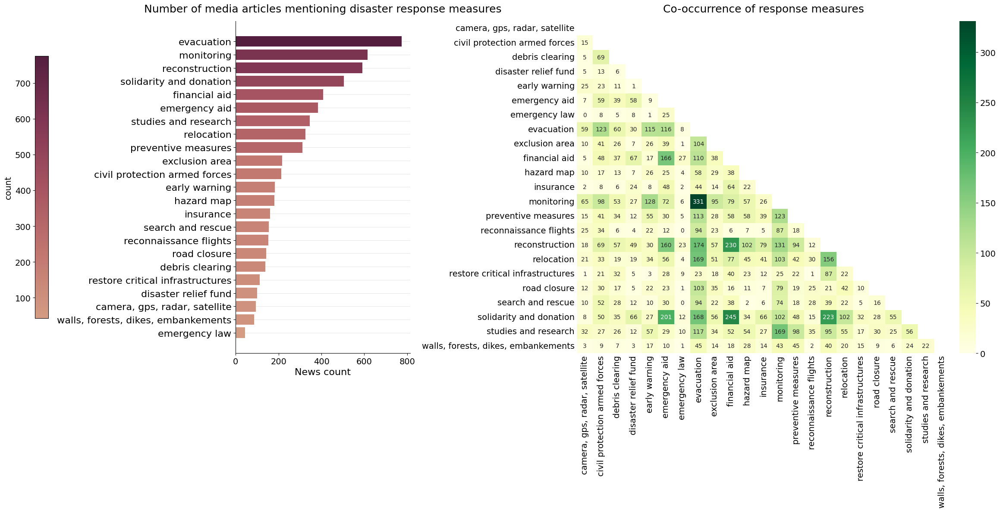

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import plotly.express as px

plt.rcParams['svg.fonttype'] = 'none'

# ============================================================
# TUNABLE PARAMETERS
# ============================================================
FIGSIZE = (24, 12)
WIDTH_RATIOS = [1, 1.2]
TITLE_SIZE = 18
LABEL_SIZE = 16
TICK_SIZE = 14

# Categories to exclude (case-insensitive match)
EXCLUDE = {"others", "other"}

# ============================================================
# LEFT PANEL DATA — bar chart of response-measure counts
# ============================================================
counts_event = (
    unique_df["strategy_llm"]
    .str.split(";").explode().str.strip()
    .value_counts().to_frame('count')
)
counts_event.reset_index(inplace=True)
merged_counts = (
    counts_event.rename(columns={"strategy_llm": "Strategy"})
    .sort_values("count", ascending=True)
)
# Remove "Others" / "Other"
merged_counts = merged_counts[~merged_counts["Strategy"].str.lower().isin(EXCLUDE)]

# ============================================================
# RIGHT PANEL DATA — co-occurrence heatmap
# ============================================================
solution_df = dfh.filter(regex=r"^Solution:").astype(int)
co_occurrence_events = solution_df.T @ solution_df
co_occurrence_events.index = co_occurrence_events.index.str.replace("Solution:", "", regex=False)
co_occurrence_events.columns = co_occurrence_events.columns.str.replace("Solution:", "", regex=False)

# Drop "Others" / "Other" from both rows and columns
keep = [c for c in co_occurrence_events.columns if c.strip().lower() not in EXCLUDE]
co_occurrence_events = co_occurrence_events.loc[keep, keep]

mask = np.triu(np.ones_like(co_occurrence_events, dtype=bool))

# ============================================================
# COLORMAP — convert Plotly Brwnyl to a matplotlib colormap
# ============================================================
def _plotly_rgb_to_tuple(c):
    if c.startswith("rgb"):
        nums = c[c.index("(")+1:c.index(")")].split(",")
        return tuple(float(n)/255 for n in nums)
    return c

brwnyl_colors = [_plotly_rgb_to_tuple(c) for c in px.colors.sequential.Brwnyl[2:]]
brwnyl_cmap = LinearSegmentedColormap.from_list("Brwnyl", brwnyl_colors)

# ============================================================
# FIGURE
# ============================================================
fig, axes = plt.subplots(
    1, 2,
    figsize=FIGSIZE,
    gridspec_kw={'width_ratios': WIDTH_RATIOS}
)

# --- LEFT: horizontal bar chart, colorbar on the LEFT edge ---
ax1 = axes[0]
bar_counts = merged_counts["count"].values
norm = plt.Normalize(vmin=bar_counts.min(), vmax=bar_counts.max())
bar_colors = brwnyl_cmap(norm(bar_counts))

ax1.barh(merged_counts["Strategy"], bar_counts, color=bar_colors)
ax1.set_xlabel("News count", fontsize=LABEL_SIZE)
ax1.set_ylabel("")
ax1.set_title("Number of media articles mentioning disaster response measures",
              fontsize=TITLE_SIZE, pad=15)
ax1.tick_params(axis='x', labelsize=TICK_SIZE)
ax1.tick_params(axis='y', labelsize=LABEL_SIZE)
ax1.grid(axis='y', linestyle='-', alpha=0.3)
ax1.set_axisbelow(True)
for spine in ['top', 'right']:
    ax1.spines[spine].set_visible(False)

sm = plt.cm.ScalarMappable(cmap=brwnyl_cmap, norm=norm)
sm.set_array([])
cbar1 = fig.colorbar(sm, ax=ax1, location='left', pad=0.5, fraction=0.035)
cbar1.ax.tick_params(labelsize=TICK_SIZE)
cbar1.set_label("count", fontsize=TICK_SIZE)

# --- RIGHT: co-occurrence heatmap, colorbar on the RIGHT edge ---
ax2 = axes[1]
sns.heatmap(
    co_occurrence_events,
    mask=mask,
    cmap="YlGn",
    annot=True,
    fmt="d",
    ax=ax2,
    cbar_kws={'pad': 0.02}
)
ax2.set_title("Co-occurrence of response measures", fontsize=TITLE_SIZE, pad=15)
ax2.tick_params(axis="both", which="both", labelsize=TICK_SIZE, length=0)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90)
ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0)

heatmap_cbar = ax2.collections[0].colorbar
heatmap_cbar.ax.tick_params(labelsize=TICK_SIZE)

plt.tight_layout()

fig.savefig(figure_path + "strategies_overview.png",
            dpi=300, bbox_inches="tight", transparent=True,
            facecolor="w", edgecolor="w")
fig.savefig(figure_path + "strategies_overview.svg",
            bbox_inches="tight", transparent=True,
            facecolor="w", edgecolor="w")

plt.show()

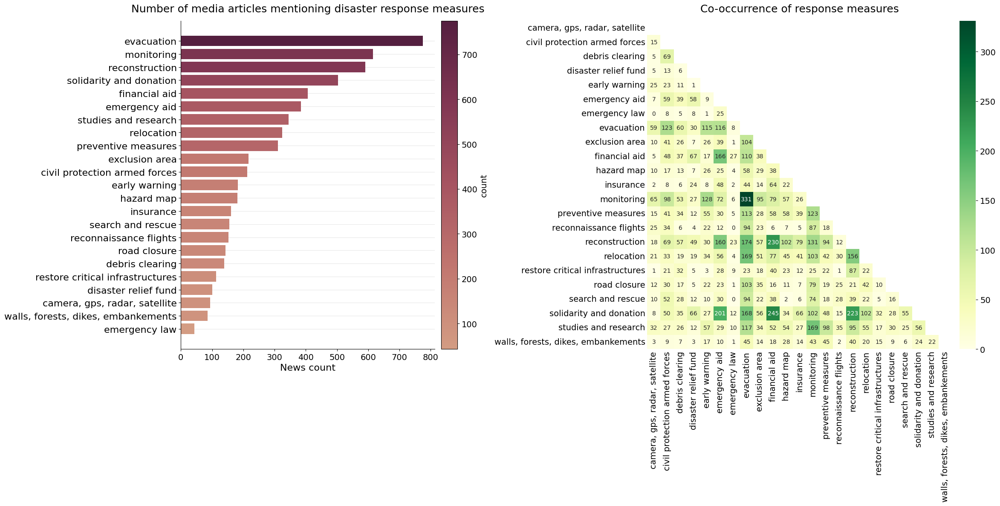

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
import plotly.express as px

plt.rcParams['svg.fonttype'] = 'none'

# ============================================================
# TUNABLE PARAMETERS
# ============================================================
FIGSIZE = (24, 12)
WIDTH_RATIOS = [1, 1.2]
TITLE_SIZE = 18
LABEL_SIZE = 16
TICK_SIZE = 14

# Categories to exclude (case-insensitive match)
EXCLUDE = {"others", "other"}

# ============================================================
# LEFT PANEL DATA — bar chart of response-measure counts
# ============================================================
counts_event = (
    unique_df["strategy_llm"]
    .str.split(";").explode().str.strip()
    .value_counts().to_frame('count')
)
counts_event.reset_index(inplace=True)
merged_counts = (
    counts_event.rename(columns={"strategy_llm": "Strategy"})
    .sort_values("count", ascending=True)
)
merged_counts = merged_counts[~merged_counts["Strategy"].str.lower().isin(EXCLUDE)]

# ============================================================
# RIGHT PANEL DATA — co-occurrence heatmap
# ============================================================
solution_df = dfh.filter(regex=r"^Solution:").astype(int)
co_occurrence_events = solution_df.T @ solution_df
co_occurrence_events.index = co_occurrence_events.index.str.replace("Solution:", "", regex=False)
co_occurrence_events.columns = co_occurrence_events.columns.str.replace("Solution:", "", regex=False)

keep = [c for c in co_occurrence_events.columns if c.strip().lower() not in EXCLUDE]
co_occurrence_events = co_occurrence_events.loc[keep, keep]

mask = np.triu(np.ones_like(co_occurrence_events, dtype=bool))

# ============================================================
# COLORMAP — convert Plotly Brwnyl to a matplotlib colormap
# ============================================================
def _plotly_rgb_to_tuple(c):
    if c.startswith("rgb"):
        nums = c[c.index("(")+1:c.index(")")].split(",")
        return tuple(float(n)/255 for n in nums)
    return c

brwnyl_colors = [_plotly_rgb_to_tuple(c) for c in px.colors.sequential.Brwnyl[2:]]
brwnyl_cmap = LinearSegmentedColormap.from_list("Brwnyl", brwnyl_colors)

# ============================================================
# FIGURE
# ============================================================
fig, axes = plt.subplots(
    1, 2,
    figsize=FIGSIZE,
    gridspec_kw={'width_ratios': WIDTH_RATIOS}
)

# --- LEFT: horizontal bar chart, colorbar on the RIGHT of the bar chart ---
ax1 = axes[0]
bar_counts = merged_counts["count"].values
norm = plt.Normalize(vmin=bar_counts.min(), vmax=bar_counts.max())
bar_colors = brwnyl_cmap(norm(bar_counts))

ax1.barh(merged_counts["Strategy"], bar_counts, color=bar_colors)
ax1.set_xlabel("News count", fontsize=LABEL_SIZE)
ax1.set_ylabel("")
ax1.set_title("Number of media articles mentioning disaster response measures",
              fontsize=TITLE_SIZE, pad=15)
ax1.tick_params(axis='x', labelsize=TICK_SIZE)
ax1.tick_params(axis='y', labelsize=LABEL_SIZE)
ax1.grid(axis='y', linestyle='-', alpha=0.3)
ax1.set_axisbelow(True)
for spine in ['top', 'right']:
    ax1.spines[spine].set_visible(False)

sm = plt.cm.ScalarMappable(cmap=brwnyl_cmap, norm=norm)
sm.set_array([])
cbar1 = fig.colorbar(sm, ax=ax1, location='right', pad=0.02)
cbar1.ax.tick_params(labelsize=TICK_SIZE)
cbar1.set_label("count", fontsize=TICK_SIZE)

# --- RIGHT: co-occurrence heatmap, colorbar on the RIGHT ---
ax2 = axes[1]
sns.heatmap(
    co_occurrence_events,
    mask=mask,
    cmap="YlGn",
    annot=True,
    fmt="d",
    ax=ax2,
    cbar_kws={'pad': 0.02}
)
ax2.set_title("Co-occurrence of response measures", fontsize=TITLE_SIZE, pad=15)
ax2.tick_params(axis="both", which="both", labelsize=TICK_SIZE, length=0)
ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90)
ax2.set_yticklabels(ax2.get_yticklabels(), rotation=0)

heatmap_cbar = ax2.collections[0].colorbar
heatmap_cbar.ax.tick_params(labelsize=TICK_SIZE)

plt.tight_layout()

fig.savefig(figure_path + "strategies_overview.png",
            dpi=300, bbox_inches="tight", transparent=True,
            facecolor="w", edgecolor="w")
fig.savefig(figure_path + "strategies_overview.svg",
            bbox_inches="tight", transparent=True,
            facecolor="w", edgecolor="w")

plt.show()

## Characteristics of the news

In [ ]:
#df_keep = unique_df[['id', 'pubtime', 'medium_code', 'doctype', 'medium_name', 'language', 'content_en','event_llm','strategy_llm','narratives']]
df_keep["pubtime"] = pd.to_datetime(df_keep["pubtime"], utc=True)
d_keep = df_keep.sort_values(by='pubtime')
# Extract only the date part (YYYY-MM-DD)
df_keep['date'] = df_keep["pubtime"].dt.date
# Floor to the start of the week (Monday)
df_keep["week"] = df_keep["pubtime"].dt.to_period("W").apply(lambda r: r.start_time)

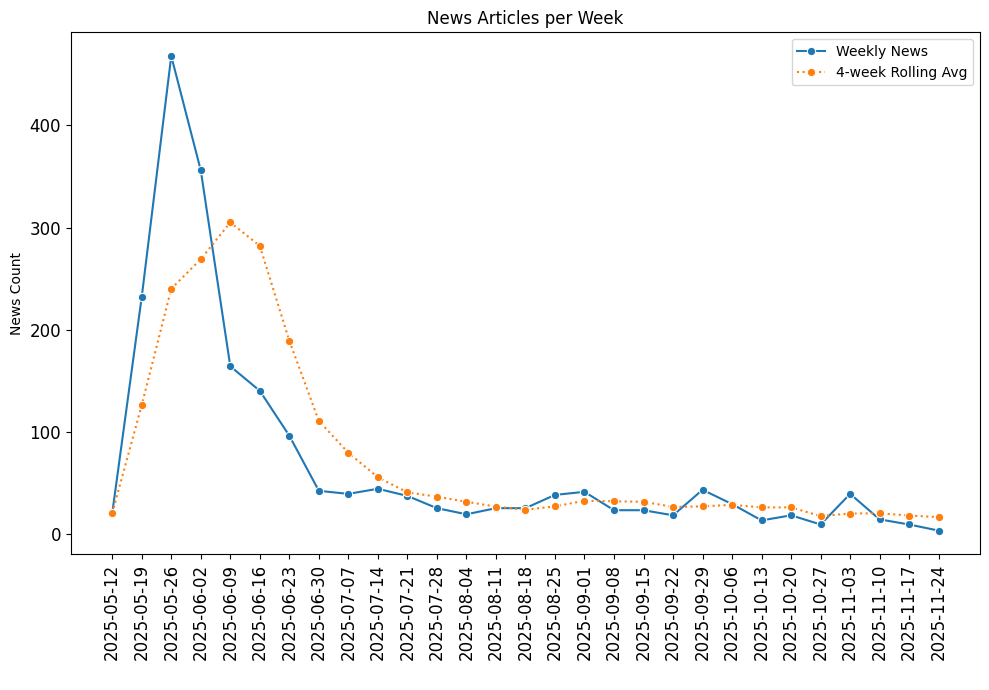

In [ ]:
weekly_counts = df_keep.groupby("week").size().reset_index(name="news_count")
weekly_counts["cumulative_news"] = weekly_counts["news_count"].cumsum()
weekly_counts["rolling_avg"] = weekly_counts["news_count"].rolling(window=4, min_periods=1).mean()

plt.figure(figsize=(10,7))
sns.lineplot(data=weekly_counts, x="week", y="news_count", marker="o", label="Weekly News")

## Cumulative trend (smooth line)
#sns.lineplot(data=weekly_counts, x="week", y="cumulative_news", marker="o", label="Cumulative News", linestyle="--")

# Rolling average trend
sns.lineplot(data=weekly_counts, x="week", y="rolling_avg", marker="o", linestyle=":", label="4-week Rolling Avg")

# Force all weekly ticks
plt.xticks(weekly_counts["week"],rotation=45)
plt.tick_params(axis="x", labelsize=12)
plt.tick_params(axis="y", labelsize=12)

plt.title("News Articles per Week")
plt.xlabel(" ")
plt.ylabel("News Count")
plt.xticks(rotation=90)
plt.tight_layout()
plt.savefig(figure_path+'NewsArtcleWeek_to20251127.svg',bbox_inches='tight', transparent = True, facecolor ="w", edgecolor ='w', dpi = 300)
plt.savefig(figure_path+'NewsArtcleWeek_to20251127.png',bbox_inches='tight', transparent = True, facecolor ="w", edgecolor ='w', dpi = 300)

In [ ]:
language = df_keep['language'].value_counts().to_frame('count')
language = language.reset_index()
language.columns = ['language', 'count']

label_map = {
    "de": "German",
    "fr": "French",
    "it": "Italian",
    "en": "English",
}

color_continuous_scale = px.colors.sequential.Brwnyl[::][2:]
plt.rcParams['svg.fonttype'] = 'none'
fig = px.bar(language,
             x="count", y="language",
             title="News content language", color = 'count',
             #color_continuous_scale=px.colors.sequential.Brwnyl[::-1])  # Inverting the color scale)
             color_continuous_scale=color_continuous_scale,
             labels={
            "count": "",   # rename x and color legend
            "language": ""  # rename y
            }
            )  # Inverting the color scale)

fig.update_layout(width=800, height=500,
        title = {"x": .55,"y": .90,"font": dict(size=20)},
        coloraxis_showscale=True,
        coloraxis_colorbar=dict(
        tickfont=dict(size=16)),
        xaxis=dict(tickfont=dict(size=16)),
        yaxis=dict(
        tickfont=dict(size=16),
        tickmode="array",
        tickvals=language["language"],
        ticktext=[label_map.get(v, v) for v in language["language"]]
    ),


)
fig.update_yaxes(autorange="reversed")
fig.update_layout(template='seaborn')
fig.update_xaxes(showgrid=False)

fig.write_image(figure_path+"type_language.svg",scale=3)
fig.write_image(figure_path+"type_language.png",scale=3)
fig.show()

In [ ]:
#Get the value in case only descriptive in the manuscript and no figure
language

,language,count
0,de,1272
1,fr,637
2,it,85
3,en,58


In [ ]:
medium = df_keep['doctype'].value_counts().to_frame('count')
medium = medium.reset_index()
medium.columns = ['doctype', 'count']

label_map = {
    "WWE": "Online media",
    "PRD": "Regional daily newspaper",
    "PND": "National daily newspaper",
    "PJO": "Regional weekly newspaper",
    "PMA": "Magazines",
    "PLD": "Local daily newspaper"
}



color_continuous_scale = px.colors.sequential.Brwnyl[::][2:]
plt.rcParams['svg.fonttype'] = 'none'
fig = px.bar(medium,
             x="count", y="doctype",
             title="Type of media", color = 'count',
             #color_continuous_scale=px.colors.sequential.Brwnyl[::-1])  # Inverting the color scale)
             color_continuous_scale=color_continuous_scale,
             labels={
            "count": "",   # rename x and color legend
            "doctype": ""  # rename y
            }
            )  # Inverting the color scale)

fig.update_layout(width=800, height=500,
        title = {"x": .55,"y": .90,"font": dict(size=20)},
        coloraxis_showscale=True,
        coloraxis_colorbar=dict(
        tickfont=dict(size=14)),
        xaxis=dict(tickfont=dict(size=16)),
        yaxis=dict(
        tickfont=dict(size=16),
        tickmode="array",
        tickvals=medium["doctype"],
        ticktext=[label_map.get(v, v) for v in medium["doctype"]]
    ),


)
fig.update_yaxes(autorange="reversed")
fig.update_layout(template='seaborn')
fig.update_xaxes(showgrid=False)

fig.write_image(figure_path+"type_media.svg",scale=3)
fig.write_image(figure_path+"type_media.png",scale=3)

fig.show()

In [ ]:
#Get the value in case only descriptive in the manuscript and no figure
medium["doctype_label"] = medium["doctype"].map(label_map).fillna(medium["doctype"])
medium

,doctype,count,doctype_label
0,WWE,1420,Online media
1,PRD,341,Regional daily newspaper
2,PND,187,National daily newspaper
3,PJO,65,Regional weekly newspaper
4,PMA,37,Magazines
5,PLD,2,Local daily newspaper


In [ ]:
online = df_keep[df_keep['doctype'] == 'WWE']
online = online['medium_name'].value_counts().to_frame('count')
online = online.reset_index()
online.columns = ['medium_name', 'count']

paper = df_keep[df_keep['doctype'] != 'WWE']
paper = paper['medium_name'].value_counts().to_frame('count')
paper = paper.reset_index()
paper.columns = ['medium_name', 'count']
q25= paper['count'].quantile(0.25)
filtered = paper[paper['count'] > 1]

color_continuous_scale = px.colors.sequential.Brwnyl[::][2:]
plt.rcParams['svg.fonttype'] = 'none'
fig = px.bar(online,
             x="count", y="medium_name",
             title="Name of online media", color = 'count',
             #color_continuous_scale=px.colors.sequential.Brwnyl[::-1])  # Inverting the color scale)
             color_continuous_scale=color_continuous_scale,
             labels={
            "count": "",   # rename x and color legend
            "medium_name": ""  # rename y
            }
            )  # Inverting the color scale)

fig.update_layout(width=800, height=500,
        title = {"x": .5,"y": .90,"font": dict(size=20)},
        coloraxis_showscale=True,
        coloraxis_colorbar=dict(
        tickfont=dict(size=14)),
        xaxis=dict(tickfont=dict(size=16)),
        yaxis=dict(
        tickfont=dict(size=16),
        tickmode="array",

    ),


)
fig.update_yaxes(autorange="reversed")
fig.update_layout(template='seaborn')
fig.update_xaxes(showgrid=False)

fig.write_image(figure_path+"name_onlinemedia.svg",scale=3)
fig.write_image(figure_path+"name_onlinemedia.png",scale=3)

fig.show()

In [ ]:
online

,medium_name,count
0,blick.ch,241
1,srf.ch,170
2,swissinfo.ch,84
3,aargauerzeitung.ch,78
4,letemps.ch,78
5,20 minuten online,73
6,rsi.ch,71
7,nzz.ch,69
8,rts.ch,66
9,24heures.ch,57


In [ ]:
#from IPython.display import Markdown, display
#display(Markdown('> '+df['content_en'][1100]))

In [ ]:
counts_event = df["event_llm"].str.split(";").explode().str.strip().value_counts().to_frame('count')
counts_event.reset_index(inplace=True)
merged_counts = (counts_event.rename(columns={"event_llm": "Hazard"})
             .sort_values("count", ascending=True))

import plotly.express as px
fig = px.bar(
    merged_counts,
    x="count",
    y="Hazard",
    orientation="h",
    color="count",                      # <-- colormap by value
    color_continuous_scale="Cividis_r",         # try also: "Blues", "Plasma", "Cividis"
    #text="occurrences",
    title="Blatten Event Description in the Media",
    labels={"count": "Count", "Hazard": "Hazard"},
)

fig.update_traces(textposition="outside", cliponaxis=False)

fig.update_layout(
    template="plotly_white",
    title=dict(x=0.5),
    height=650,
    width=1200,
    margin=dict(l=220, r=60, t=80, b=40),
    # horizontal gridlines only:
    xaxis=dict(showgrid=False, zeroline=False),
    yaxis=dict(showgrid=True, categoryorder="array", categoryarray=merged_counts["Hazard"].tolist()),
)

fig.show()


#fig.write_html("/content/drive/MyDrive/deep_learning_7_SV/Blatten_news/Event_description.html")
#fig.write_image("/content/drive/MyDrive/deep_learning_7_SV/Blatten_news/Event_description_4.png",scale=3)
# scale=3 => 3600x1950 px output (typically plenty for 300+ dpi in documents)

## Analysis of the news content (authomatically translated in English)

In [ ]:
npr = unique_df.copy()
npr.reset_index(inplace = True)

In [ ]:
import requests
def britishize(string):
    url ="https://raw.githubusercontent.com/hyperreality/American-British-English-Translator/master/data/american_spellings.json"
    american_to_british_dict = requests.get(url).json()

    for american_spelling, british_spelling in american_to_british_dict.items():
        string = string.replace(american_spelling, british_spelling)

    return string

In [ ]:
#Rename column to align with previous version of the script
npr['clean_content_en'] = npr['content_en'].astype(str)

In [ ]:
#We want all abstracts in british english
#Need a good network to run this because of the url request in the britishize function.
#npr['content_translated_british'] = npr['clean_content_en'].apply(lambda x: britishize(x))

In [ ]:
#npr["abstract_clean"] = (
#    npr["Abstract_british"]
#      .str.replace(r"\s*right\s+reserve\.?\s*$", "", case=False, regex=True)
#      .str.replace(r"\s+", " ", regex=True)
#      .str.strip())

In [ ]:
def lemmatize_without_names_places(text):
    doc = nlp(str(text))
    lemmas = [
        token.lemma_
        for token in doc
        # keep only tokens that are NOT named entities of these types
        if token.ent_type_ not in {"PERSON", "ORG", "GPE", "LOC"}
    ]
    return " ".join(lemmas)

In [ ]:
npr["abstract_lemmatized"] = npr["clean_content_en"].apply(lemmatize_without_names_places)

In [ ]:
npr['narratives_lemmatized'] = npr['narratives'].apply(lemmatize_without_names_places)

In [ ]:
#Use the spacy lemmatizer to get the best result so far
#npr['abstract_lemmatized'] = npr['Abstract_british'].apply(lambda row: " ".join([w.lemma_ for w in nlp(row)]))
#npr['abstract_lemmatized'] = npr['content_translated_british'].apply(lambda row: " ".join([w.lemma_ for w in nlp(row)]))

In [ ]:
nlp.Defaults.stop_words |= {'Blatten', 'blatten','monday', 'tuesday', 'wednesday', 'friday', 'thursday','saturday', 'sunday','village','swiss', 'press','conference', 'press conference', 'switzerland', 'Switzerland', 'lötschental', 'blatten lötschental', 'valais', 'blatten vs', 'vs','cubic', 'metre',
                            'cubic metre', 'million metre','million cubic','die', 'ist', 'und', 'der', 'wir', 'es', 'das', 'ein', 'den', 'zu', 'haben', 'nicht', 'für', 'sind', 'eine', 'ich', 'dass', 'mit', 'werden', 'house',
                            'de', 'la', 'le', 'les', 'et', 'des', 'nous', 'est', 'pas', 'du', 'en', 'il', 'un', 'pour',
                            'plus', 'une', 'dans', 'que', 'se', 'inhabitant','ticker', 'news ticker', 'qr', 'qr code',
                            'night', 'day', 'journal', 'news', 'win', 'play live', 'live win', 'quiz', 'live quiz'}

stop_words_2 = nlp.Defaults.stop_words

In [ ]:
BIGRAM_SYNONYMS = {
    #"million cubic": "cubic meter",
    "mountain crash": "mountain fall",
    "municipality blatten": "municipality",
    "municipality Blatten": "municipality"
    #"meter meter": "cubic meter"

}

def normalize_synonyms(text: str) -> str:
    txt = text.lower()
    for variant, canon in BIGRAM_SYNONYMS.items():
        txt = re.sub(rf"\b{re.escape(variant)}\b", canon, txt)

    return txt

In [ ]:
# Matches a sentence that contains download or quiz related news (case-insensitive)
SENT_WITH_BAD_WORD = re.compile(
    r'(?is)(?:^|(?<=[.!?]))\s*[^.!?]*\b(?:download|quiz)\b[^.!?]*[.!?]?\s*'
)

def remove_sentences_with_download_quiz(text: str) -> str:
    if not isinstance(text, str) or not text.strip():
        return text
    cleaned = SENT_WITH_BAD_WORD.sub(" ", text)
    # tidy spacing
    cleaned = re.sub(r'\s+', ' ', cleaned).strip()
    return cleaned

In [ ]:
# Apply synonym normalization
npr['abstract_norm'] = npr['abstract_lemmatized'].apply(normalize_synonyms)
npr['abstract_norm'] = npr['abstract_norm'].apply(remove_sentences_with_download_quiz)

In [ ]:
# Apply synonym normalization
npr['narratives_norm'] = npr['narratives_lemmatized'].apply(normalize_synonyms)
npr['narratives_norm'] = npr['narratives_norm'].apply(remove_sentences_with_download_quiz)

In [ ]:
#Bigrams
tfidf = TfidfVectorizer(
    max_df=0.95, min_df=2, ngram_range=(2,2), stop_words=list(stop_words_2)
)
dtm = tfidf.fit_transform(npr["abstract_norm"])
tfidf_weights_22 = [(word, dtm.getcol(idx).sum()) for word, idx in tfidf.vocabulary_.items()]
feature_names_22 = tfidf.get_feature_names_out()
occ = np.asarray(dtm.sum(axis=0)).ravel().tolist()
counts_22 = pd.DataFrame({'term': tfidf.get_feature_names_out(), 'occurrences': occ})
counts_22 = counts_22.sort_values(by='occurrences', ascending=False)

In [ ]:
weights = np.asarray(dtm.mean(axis=0)).ravel().tolist()
weights_22= pd.DataFrame({'term': tfidf.get_feature_names_out(), 'weight': weights})
weights_22 = weights_22.sort_values(by='weight', ascending=False)

In [ ]:
#monograms
tfidf = TfidfVectorizer(
    max_df=0.95, min_df=2, ngram_range=(1,1), stop_words=list(stop_words_2)
)
dtm = tfidf.fit_transform(npr["abstract_norm"])
tfidf_weights_11 = [(word, dtm.getcol(idx).sum()) for word, idx in tfidf.vocabulary_.items()]
feature_names_11 = tfidf.get_feature_names_out()
occ = np.asarray(dtm.sum(axis=0)).ravel().tolist()
counts_11 = pd.DataFrame({'term': tfidf.get_feature_names_out(), 'occurrences': occ})
counts_11 = counts_11.sort_values(by='occurrences', ascending=False)

In [ ]:
#mono-bigrams
tfidf = TfidfVectorizer(
    max_df=0.95, min_df=2, ngram_range=(1,2),
    stop_words=list(stop_words_2),
)
dtm = tfidf.fit_transform(npr["abstract_norm"])
tfidf_weights_12 = [(word, dtm.getcol(idx).sum()) for word, idx in tfidf.vocabulary_.items()]
feature_names_12 = tfidf.get_feature_names_out()
occ = np.asarray(dtm.sum(axis=0)).ravel().tolist()
counts_12 = pd.DataFrame({'term': tfidf.get_feature_names_out(), 'occurrences': occ})
counts_12.sort_values(by='occurrences', ascending=False).head(50)

,term,occurrences
54517,mountain,54.258568
35297,glacier,49.611814
45764,landslide,41.361649
52953,million,41.027145
94459,year,40.836280
13547,collapse,39.438089
74039,rock,39.043243
20052,debris,38.829711
89932,valley,37.782517
33542,franc,36.788085


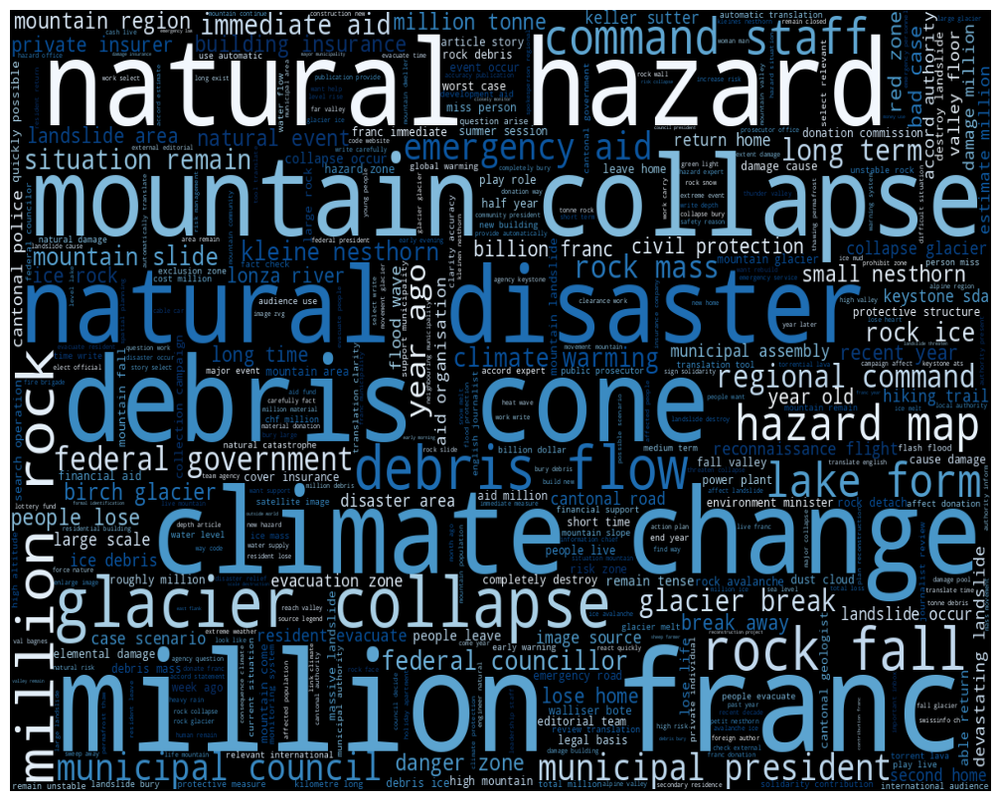

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

csfont = {'fontname': 'Arial'}

w22 = WordCloud(
    width=1200,
    height=800,
    background_color="black",
    mode="RGBA",
    max_words=400,
    colormap="Blues",          # nicer gradient
    prefer_horizontal=0.9,
    relative_scaling=0.5,
    contour_width=2,
    contour_color="grey",
    random_state=42,
    # font_path="Arial.ttf",    # uncomment if you have a specific font file
).fit_words(dict(tfidf_weights_22))

fig, ax = plt.subplots(figsize=(10, 8))

ax.imshow(w22, aspect="auto")
# ax.set_title("Bigram Word Cloud", **csfont, fontsize=18)  # optional title
ax.axis("off")

plt.tight_layout(pad=0.5)

figure_name_cloud = "content_Bigram_beautified"
plt.savefig(figure_path + figure_name_cloud + ".png",
            bbox_inches="tight", dpi=300)
plt.savefig(figure_path + figure_name_cloud + ".png",
            bbox_inches="tight", dpi=300)
plt.show()

### Topic Modelling with NMF

In [ ]:
from sklearn.decomposition import NMF

In [ ]:
#npr.reset_index(inplace = True)
#npr.drop('level_0', inplace = True, axis = 1)
#npr.drop('index', inplace = True, axis = 1)

In [ ]:
#bigrams
tfidf = TfidfVectorizer(
    max_df=0.95, min_df=2, ngram_range=(1,2),
    stop_words=list(stop_words_2),
)
dtm = tfidf.fit_transform(npr["abstract_norm"])

In [ ]:
# Fit NMF
nmf_model = NMF(n_components=18, random_state=43)
nmf_model.fit(dtm)

# How many top words per topic
n_top_words = 20   # change to 10 if you like

feature_names = tfidf.get_feature_names_out()
topics_list = []

for index, topic in enumerate(nmf_model.components_):
    # indices of top n words, sorted from highest to lowest weight
    top_indices = topic.argsort()[-n_top_words:][::-1]
    top_words = [feature_names[i] for i in top_indices]

    print(f"TOP {n_top_words} WORDS FOR TOPIC #{index}")
    print(top_words)
    print()

    topics_list.append(top_words)

# ---- Save to CSV (one row per topic, one column per rank) ----
topics_df = pd.DataFrame(
    topics_list,
    index=[f"topic_{i}" for i in range(len(topics_list))]
)

TOP 20 WORDS FOR TOPIC #0
['people', 'mountain', 'live', 'valley', 'home', 'life', 'lose', 'know', 'time', 'year', 'disaster', 'want', 'family', 'leave', 'like', 'school', 'long', 'nature', 'come', 'president']

TOP 20 WORDS FOR TOPIC #1
['aid', 'franc', 'million', 'million franc', 'fund', 'federal', 'support', 'government', 'immediate', 'emergency', 'municipality', 'emergency aid', 'decide', 'measure', 'immediate aid', 'disaster', 'contribution', 'law', 'urgent', 'money']

TOP 20 WORDS FOR TOPIC #2
['climate', 'change', 'climate change', 'permafrost', 'warming', 'increase', 'heat', 'country', 'risk', 'year', 'temperature', 'weather', 'emission', 'global', 'degree', 'event', 'link', 'climate warming', 'warm', 'rise']

TOP 20 WORDS FOR TOPIC #3
['insurance', 'damage', 'insurer', 'building', 'loss', 'insure', 'pool', 'private', 'natural', 'premium', 'private insurer', 'franc', 'year', 'risk', 'building insurance', 'company', 'percent', 'flood', 'million franc', 'cause']

TOP 20 WORDS FOR

In [ ]:
topics_df = pd.DataFrame(topics_list)
topics_df = topics_df.T
topics_df = topics_df.add_prefix('Topic_')
topics_df = topics_df.iloc[::-1]
topics_df.to_csv(file_path+"nmf_topics_top_words.csv", index=True)

In [ ]:
#This are the suggested title for the topics above from 0 to len(topics)
topics = ['community_disruption',
          'fund_immediate',
          'climate_change',
          'insurance_damage',
          'translation_deepl',
          'rockfall_landslide',
          'flood_debris_lake',
          'hazard_risk_map',
          'accommodation_tourism',
          'municipality_donation',
          'evacuation_situation',
          'human_casualty',
          'glacier_collapse',
          'donation_redistribution',
          'online_collection_campaign',
          'monitoring_detection',
          'services_intervention',
          'reconstruction_rebuild']

In [ ]:
nc = len(nmf_model.components_)

In [ ]:
topic_df3 = pd.DataFrame(
    nmf_model.transform(dtm),
    columns=["topic_{}".format(i) for i in range(nc)]
).astype(float)
topic_df3.index = npr.index
npr_topics = pd.concat([npr, topic_df3], axis=1)

In [ ]:
npr_topics.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2052 entries, 0 to 2051
Data columns (total 66 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   index                    2052 non-null   int64  
 1   Unnamed: 0               2052 non-null   int64  
 2   id                       2052 non-null   int64  
 3   pubtime                  2052 non-null   object 
 4   medium_code              2052 non-null   object 
 5   medium_name              2052 non-null   object 
 6   rubric                   1360 non-null   object 
 7   regional                 99 non-null     object 
 8   doctype                  2052 non-null   object 
 9   doctype_description      2052 non-null   object 
 10  language                 2052 non-null   object 
 11  char_count               2052 non-null   int64  
 12  dateline                 353 non-null    object 
 13  head                     2052 non-null   object 
 14  subhead                 

In [ ]:
topic_results = nmf_model.transform(dtm)

In [ ]:
topic_results.shape

(2052, 18)

In [ ]:
#from wordcloud import WordCloud

# Example: Assuming 'nmf_model' and 'vectorizer' are defined
#def plot_word_cloud(model, feature_names, n_words=10):
#    for topic_idx, topic in enumerate(model.components_):
#        plt.figure(figsize=(10, 5))
#        wordcloud = WordCloud(width=800, height=400, background_color='white').generate(" ".join(
#            [feature_names[i] for i in topic.argsort()[:-n_words - 1:-1]]))
#        plt.imshow(wordcloud, interpolation="bilinear")
#        plt.axis('off')
#        plt.title(f'Top words in Topic {topic_idx}')
#        plt.show()

#plot_word_cloud(nmf_model, tfidf.get_feature_names_out())  # Make sure vectorizer is defined

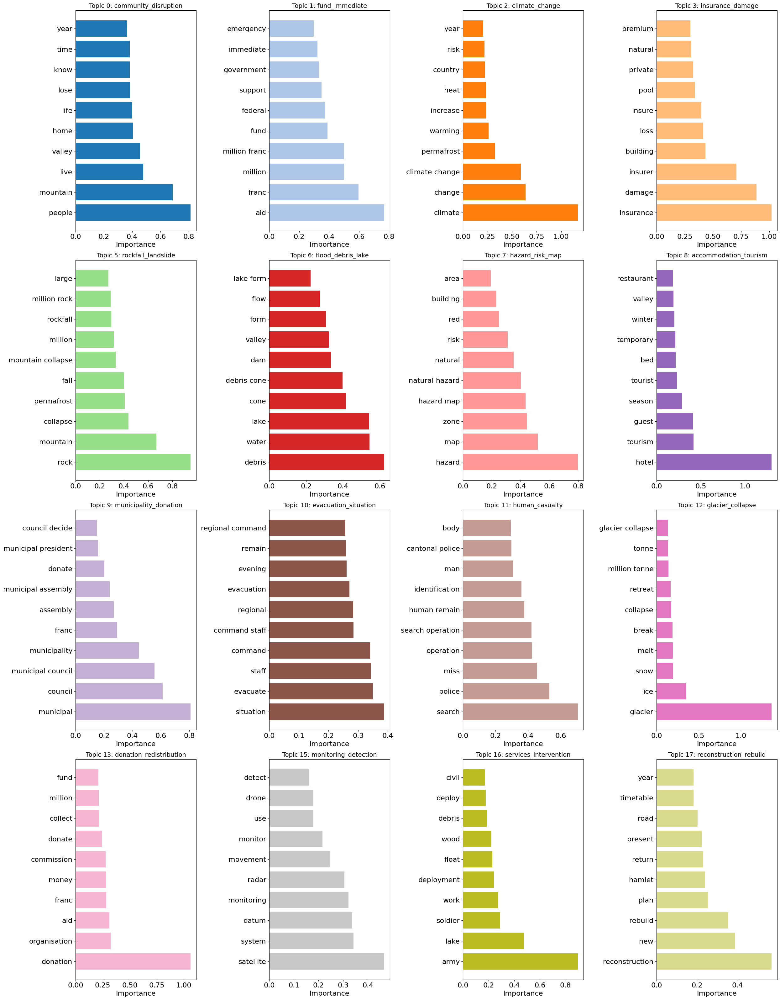

In [ ]:
# - nmf_model: your fitted NMF model
# - vectorizer: the vectorizer used to create the document-term matrix
# - dtm: your document-term matrix
# - topic_results: the document-topic matrix from NMF

# Example: Assuming topic_results is already defined and contains the document-topic distribution
topic_results = nmf_model.transform(dtm)

# Topic mapping
topic_mapping = {i: label for i, label in enumerate(topics)}

base_palette = sns.color_palette("tab20", n_colors=len(topic_mapping))
color_by_topic = {topic_idx: base_palette[i] for i, topic_idx in enumerate(sorted(topic_mapping.keys()))}

# Count the number of documents for each topic
doc_topic_counts = topic_results.argmax(axis=1)
topic_member_counts = np.bincount(doc_topic_counts)

# Exclude topics 4 and 14 only
exclude_topics = [4, 14]
valid_topics = np.array([
    topic_idx for topic_idx in sorted(topic_mapping.keys())
    if topic_idx not in exclude_topics
])


# Function to get the top words for each topic
def get_top_words(model, feature_names, valid_topics, n_words=10):
    topic_words = {}
    for topic_idx in valid_topics:
        top_indices = model.components_[topic_idx].argsort()[-n_words:][::-1]  # Get top word indices
        topic_words[topic_idx] = [feature_names[i] for i in top_indices]  # Get top words
    return topic_words

# Get the top words for valid topics
top_words = get_top_words(nmf_model, tfidf.get_feature_names_out(), valid_topics)

# Create a grid of bar plots for valid topics
n_topics = len(top_words)
n_words = 10  # Number of words per topic

# Determine the number of rows and columns for the plots
n_cols = 4  # Number of columns
n_rows = int(np.ceil(n_topics / n_cols))  # Calculate rows needed

# Generate a color palette with enough colors for all topics
colors = sns.color_palette("husl", n_topics)

fig, axs = plt.subplots(n_rows, n_cols, figsize=(25, 8 * n_rows))
axs = axs.flatten()  # Flatten the array of axes for iteration

# Plotting each topic's top words
for i, (topic_idx, words) in enumerate(top_words.items()):
    # Create a DataFrame for the top words and their relevance
    word_indices = np.arange(n_words)
    word_counts = nmf_model.components_[topic_idx, np.argsort(nmf_model.components_[topic_idx])[-n_words:][::-1]]

    # Create the bar plot
    axs[i].barh(word_indices, word_counts, color=color_by_topic[topic_idx])  # Use a different color for each plot
    axs[i].set_yticks(word_indices)
    axs[i].set_yticklabels(words)


    # Set title to include topic number and label
    topic_label = topic_mapping.get(topic_idx, "Unknown Topic")  # Fetch the label
    axs[i].set_title(f'Topic {topic_idx}: {topic_label}', fontsize=14)
    axs[i].set_xlabel('Importance', fontsize=16)
    # Change tick label size
    axs[i].tick_params(axis='both', labelsize=16)  # Adjust labelsize as needed


# Remove any empty subplots
for j in range(n_topics, n_rows * n_cols):
    fig.delaxes(axs[j])

plt.tight_layout()
figure_name_topiccount = "topic_word_count"
plt.savefig(figure_path + figure_name_topiccount + ".png",
            bbox_inches="tight", dpi=400,pad_inches=0.2,
            facecolor='auto', edgecolor='auto',backend=None)

plt.savefig(figure_path + figure_name_topiccount + ".svg",
            bbox_inches="tight", dpi=400,pad_inches=0.2,
            facecolor='auto', edgecolor='auto',backend=None)

plt.show()

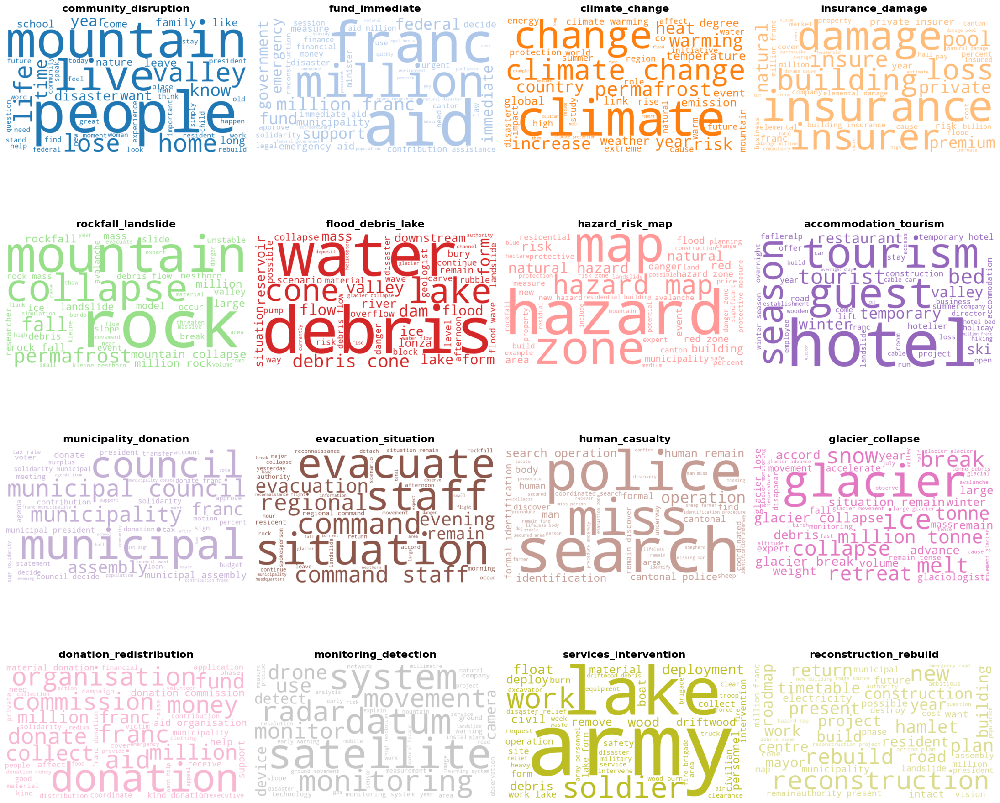

In [ ]:
from matplotlib.colors import to_rgb

# Topic-document matrix
topic_results = nmf_model.transform(dtm)

# Topic mapping
topic_mapping = {i: label for i, label in enumerate(topics)}

# Keep your topic color logic
base_palette = sns.color_palette("tab20", n_colors=len(topic_mapping))
color_by_topic = {
    topic_idx: base_palette[i]
    for i, topic_idx in enumerate(sorted(topic_mapping.keys()))
}

# Exclude topics 4 and 14 only
exclude_topics = [4, 14]
valid_topics = np.array([
    topic_idx for topic_idx in sorted(topic_mapping.keys())
    if topic_idx not in exclude_topics
])

feature_names = tfidf.get_feature_names_out()

# Build frequency dictionary for wordclouds
def get_topic_word_freqs(model, feature_names, valid_topics, n_words=40):
    topic_word_freqs = {}

    for topic_idx in valid_topics:
        top_indices = model.components_[topic_idx].argsort()[-n_words:][::-1]
        freqs = {
            feature_names[i]: float(model.components_[topic_idx, i])
            for i in top_indices
        }
        topic_word_freqs[topic_idx] = freqs

    return topic_word_freqs


topic_word_freqs = get_topic_word_freqs(
    nmf_model,
    feature_names,
    valid_topics,
    n_words=50
)

# Function to keep one color family per topic
def make_single_color_func(rgb_color):
    r, g, b = [int(c * 255) for c in rgb_color]

    def single_color_func(word, font_size, position, orientation, random_state=None, **kwargs):
        return f"rgb({r}, {g}, {b})"

    return single_color_func


# Layout
n_topics = len(topic_word_freqs)
n_cols = 4
n_rows = int(np.ceil(n_topics / n_cols))

fig, axs = plt.subplots(n_rows, n_cols, figsize=(22, 5 * n_rows))
axs = np.array(axs).flatten()

for i, topic_idx in enumerate(topic_word_freqs.keys()):
    freqs = topic_word_freqs[topic_idx]
    topic_color = color_by_topic[topic_idx]
    color_func = make_single_color_func(topic_color)

    wc = WordCloud(
        width=900,
        height=500,
        background_color="white",
        prefer_horizontal=0.9,
        max_words=50,
        relative_scaling=0.5,
        random_state=42,
        collocations=False
    ).generate_from_frequencies(freqs)

    wc = wc.recolor(color_func=color_func)

    axs[i].imshow(wc, interpolation="bilinear")
    axs[i].axis("off")

    topic_label = topic_mapping.get(topic_idx, f"Topic {topic_idx}")
    axs[i].set_title(
        f"{topic_label}",
        fontsize=16,
        fontweight="bold",
        pad=10
    )

# Remove empty axes
for j in range(n_topics, len(axs)):
    fig.delaxes(axs[j])

plt.tight_layout()

figure_name_topiccloud = "topic_wordclouds"

plt.savefig(
    figure_path + figure_name_topiccloud + ".png",
    bbox_inches="tight",
    dpi=400,
    pad_inches=0.2,
    facecolor="white"
)

plt.savefig(
    figure_path + figure_name_topiccloud + ".svg",
    bbox_inches="tight",
    dpi=400,
    pad_inches=0.2,
    facecolor="white"
)

plt.show()

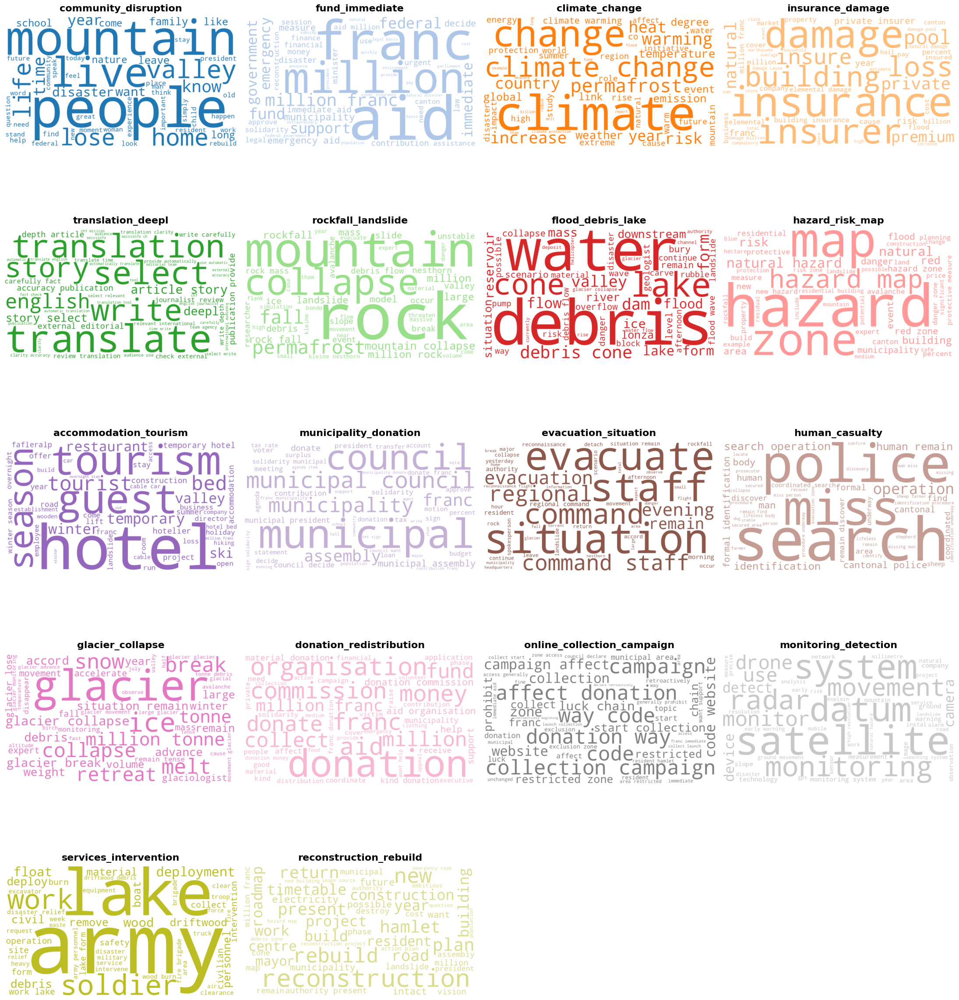

In [ ]:
from matplotlib.colors import to_rgb

# Topic-document matrix
topic_results = nmf_model.transform(dtm)

# Topic mapping
topic_mapping = {i: label for i, label in enumerate(topics)}

# Keep your topic color logic
base_palette = sns.color_palette("tab20", n_colors=len(topic_mapping))
color_by_topic = {
    topic_idx: base_palette[i]
    for i, topic_idx in enumerate(sorted(topic_mapping.keys()))
}

# Count dominant topic per document
doc_topic_counts = topic_results.argmax(axis=1)
topic_member_counts = np.bincount(doc_topic_counts)

# Filter topics with enough documents
valid_topics = np.where(topic_member_counts >= 40)[0]

feature_names = tfidf.get_feature_names_out()

# Build frequency dictionary for wordclouds
def get_topic_word_freqs(model, feature_names, valid_topics, n_words=40):
    topic_word_freqs = {}
    for topic_idx in valid_topics:
        top_indices = model.components_[topic_idx].argsort()[-n_words:][::-1]
        freqs = {
            feature_names[i]: float(model.components_[topic_idx, i])
            for i in top_indices
        }
        topic_word_freqs[topic_idx] = freqs
    return topic_word_freqs

topic_word_freqs = get_topic_word_freqs(
    nmf_model,
    feature_names,
    valid_topics,
    n_words=50
)

# Function to keep one color family per topic
def make_single_color_func(rgb_color):
    r, g, b = [int(c * 255) for c in rgb_color]

    def single_color_func(word, font_size, position, orientation, random_state=None, **kwargs):
        return f"rgb({r}, {g}, {b})"

    return single_color_func

# Layout
n_topics = len(topic_word_freqs)
n_cols = 4
n_rows = int(np.ceil(n_topics / n_cols))

fig, axs = plt.subplots(n_rows, n_cols, figsize=(22, 5 * n_rows))
axs = np.array(axs).flatten()

for i, topic_idx in enumerate(topic_word_freqs.keys()):
    freqs = topic_word_freqs[topic_idx]
    topic_color = color_by_topic[topic_idx]
    color_func = make_single_color_func(topic_color)

    wc = WordCloud(
        width=900,
        height=500,
        background_color="white",
        prefer_horizontal=0.9,
        max_words=50,
        relative_scaling=0.5,
        random_state=42,
        collocations=False
    ).generate_from_frequencies(freqs)

    wc = wc.recolor(color_func=color_func)

    axs[i].imshow(wc, interpolation="bilinear")
    axs[i].axis("off")

    topic_label = topic_mapping.get(topic_idx, f"Topic {topic_idx}")
    axs[i].set_title(
        f"{topic_label}",
        fontsize=16,
        fontweight="bold",
        pad=10
    )

# Remove empty axes
for j in range(n_topics, len(axs)):
    fig.delaxes(axs[j])

plt.tight_layout()

figure_name_topiccloud = "topic_wordclouds"

plt.savefig(
    figure_path + figure_name_topiccloud + ".png",
    bbox_inches="tight",
    dpi=400,
    pad_inches=0.2,
    facecolor="white"
)

plt.savefig(
    figure_path + figure_name_topiccloud + ".svg",
    bbox_inches="tight",
    dpi=400,
    pad_inches=0.2,
    facecolor="white"
)

plt.show()

In [ ]:
# Create a DataFrame to map topics to their counts and labels
topic_counts_df = pd.DataFrame({
    'Topic': np.arange(len(topic_member_counts)),
    'Count': topic_member_counts
})
topic_counts_df.sort_values(by='Count', ascending=False)

,Topic,Count
0,0,223
6,6,194
10,10,172
17,17,166
1,1,156
2,2,142
5,5,136
3,3,124
12,12,105
13,13,98


In [ ]:
from sklearn.manifold import TSNE

# Assuming 'topic_results' is defined as your document-topic matrix

# Topic mapping
topic_mapping = {i: label for i, label in enumerate(topics)}

# Choose topics you want to exclude by number
excluded_topics = {4,14}

# Count number of documents for each topic
doc_topic_counts = np.bincount(topic_results.argmax(axis=1))

valid_topics = np.where(doc_topic_counts >= 5)[0]

# Allowed topics = valid topics minus the excluded ones
allowed_topics = np.setdiff1d(valid_topics, list(excluded_topics))

# Perform t-SNE on valid topic results
# We need to select only columns corresponding to valid topics
valid_topic_indices = np.isin(topic_results.argmax(axis=1), allowed_topics)
tsne_model = TSNE(n_components=2, random_state=0, perplexity=30, verbose=1)
tsne_results = tsne_model.fit_transform(topic_results[valid_topic_indices])

# Create a DataFrame for t-SNE results
tsne_df = pd.DataFrame(data=tsne_results, columns=['Dim 1', 'Dim 2'])

# Re-map topics to valid ones based on the original topic results
tsne_df['Topic'] = topic_results[valid_topic_indices].argmax(axis=1)

# Map topics to labels
tsne_df['Topic Label'] = tsne_df['Topic'].map(topic_mapping)

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1961 samples in 0.001s...
[t-SNE] Computed neighbors for 1961 samples in 0.108s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1961
[t-SNE] Computed conditional probabilities for sample 1961 / 1961
[t-SNE] Mean sigma: 0.027272
[t-SNE] KL divergence after 250 iterations with early exaggeration: 69.422775
[t-SNE] KL divergence after 1000 iterations: 0.836282


In [ ]:
npr["pubtime"] = pd.to_datetime(npr["pubtime"], utc=True)
npr = npr.sort_values(by='pubtime')
# Extract only the date part (YYYY-MM-DD)
npr['date'] = npr["pubtime"].dt.date
# Floor to the start of the week (Monday)

In [ ]:
#Add week column to a new copied dataframe
npr_time = npr_topics.copy()
npr_time["pubtime"] = pd.to_datetime(npr_time["pubtime"], utc=True)
npr_time = npr_time.sort_values(by='pubtime')
# Extract only the date part (YYYY-MM-DD)
npr_time['date'] = npr_time["pubtime"].dt.date
# Floor to the start of the week (Monday)
npr_time["week"] = npr_time["pubtime"].dt.to_period("W").apply(lambda r: r.start_time)
npr_time["day"] = npr_time["pubtime"].dt.normalize().dt.tz_localize(None)

#change columns name to topic labels
rename_dict = {
    f'topic_{i}': topic_name
    for i, topic_name in enumerate(topics, start=0)
}

npr_time.rename(columns=rename_dict, inplace=True)

In [ ]:
topic_cols = npr_time.loc[:, "community_disruption":"reconstruction_rebuild"].columns   # the 18 topic columns
npr_time["topic_max_weight"] = npr_time[topic_cols].max(axis=1)
npr_time["topic_dominant"] = npr_time[topic_cols].idxmax(axis=1)

# Articles with all-zero weights have no dominant topic (idxmax would otherwise return the first column)
npr_time.loc[npr_time["topic_max_weight"] == 0, "topic_dominant"] = None

npr_time["topic_dominant_with_weight"] = (npr_time["topic_dominant"] + " (" + npr_time["topic_max_weight"].round(3).astype(str) + ")")

print(len(topic_cols), "topic columns")
print(npr_time[["topic_dominant", "topic_max_weight", "topic_dominant_with_weight"]].head())

18 topic columns
            topic_dominant  topic_max_weight    topic_dominant_with_weight
653     rockfall_landslide          0.037047    rockfall_landslide (0.037)
937     rockfall_landslide          0.057367    rockfall_landslide (0.057)
1743  evacuation_situation          0.091298  evacuation_situation (0.091)
544   evacuation_situation          0.180906  evacuation_situation (0.181)
1920  evacuation_situation          0.089759   evacuation_situation (0.09)


                  Topic   Slope  Intercept     R2      p  NumWeeks  NumArticles  p_fdr  Trend
       glacier_collapse  0.0031     0.1045 0.1639 0.1917        12          105 0.5112 stable
         fund_immediate  0.0015     0.0713 0.1421 0.1501        16          156 0.4804 stable
 reconstruction_rebuild  0.0005     0.0803 0.0155 0.5813        22          166 0.6890 stable
     rockfall_landslide -0.0001     0.0902 0.0016 0.8790        17          136 0.8790 stable
   community_disruption -0.0003     0.0508 0.0245 0.4868        22          223 0.6890 stable
         climate_change -0.0004     0.0982 0.0131 0.6029        23          142 0.6890 stable
        hazard_risk_map -0.0004     0.1291 0.0049 0.7686        20           97 0.8198 stable
  accommodation_tourism -0.0007     0.1204 0.0153 0.6028        20           85 0.6890 stable
donation_redistribution -0.0009     0.1167 0.0259 0.5369        17           98 0.6890 stable
       insurance_damage -0.0010     0.1183 0.0318 0.4273    

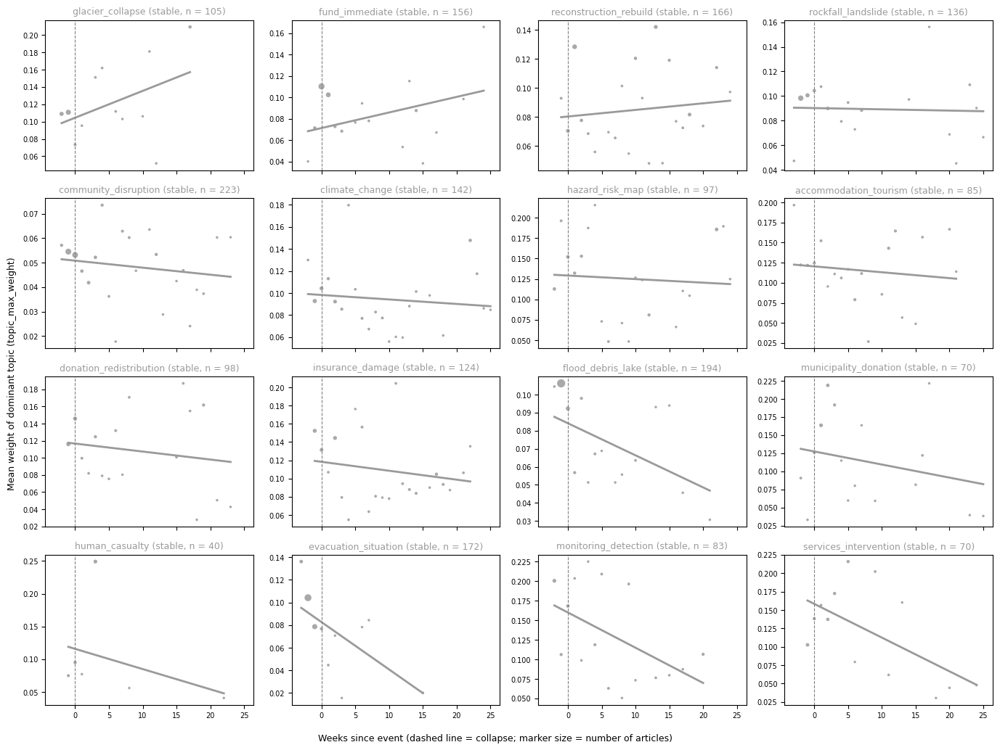

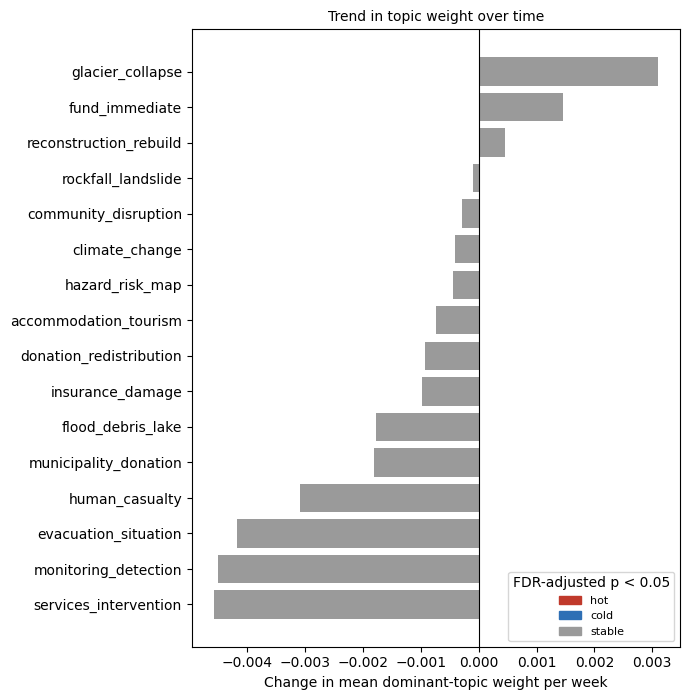

In [ ]:
#Hot/cold topics follwing method from BertTopic.
#For each topic and week, it averages the weight of the dominant topic
#among the articles where that topic is dominant. A rising slope means those articles
#become more focused on the topic (higher weights), even if fewer of them are published.
#Whether a topic gains or loses prominence in the coverage is
#requires using each topic's share of all articles per week which is what we test next

from scipy.stats import linregress
from statsmodels.stats.multitest import multipletests

WEIGHT_COL = "topic_max_weight"      # or "topic_max_share" if you created the normalised version
BOILERPLATE = ["translation_deepl", "online_collection_campaign"]
EVENT_DATE = pd.Timestamp("2025-05-28")

df_t = npr_time.drop(columns=["Unnamed: 0"], errors="ignore").copy()
df_t = df_t.dropna(subset=["topic_dominant"])
df_t = df_t[~df_t["topic_dominant"].isin(BOILERPLATE)]

# Week as a number: weeks since the event (negative = before the collapse)
df_t["week"] = pd.to_datetime(df_t["week"])
df_t["week_num"] = (df_t["week"] - EVENT_DATE).dt.days // 7

# --- Step 1: mean weight of the dominant topic per topic x week ---
agg = (df_t.groupby(["topic_dominant", "week_num"], as_index=False)
           .agg(MeanWeight=(WEIGHT_COL, "mean"),
                n_articles=(WEIGHT_COL, "size")))

# --- Step 2: linear regression per topic over weeks ---
rows = []
for topic, g in agg.groupby("topic_dominant"):
    g = g.sort_values("week_num")
    n_weeks = g["week_num"].nunique()
    if n_weeks >= 3:
        res = linregress(g["week_num"], g["MeanWeight"])
        slope, intercept, r2, p = res.slope, res.intercept, res.rvalue ** 2, res.pvalue
    else:
        slope = intercept = r2 = p = np.nan
    rows.append({"Topic": topic, "Slope": slope, "Intercept": intercept, "R2": r2,
                 "p": p, "NumWeeks": int(n_weeks), "NumArticles": int(g["n_articles"].sum())})

trend_df = pd.DataFrame(rows)

# Adjust for multiple testing, then classify: hot / cold only if significant
valid = trend_df["p"].notna()
trend_df.loc[valid, "p_fdr"] = multipletests(trend_df.loc[valid, "p"], method="fdr_bh")[1]
trend_df["Trend"] = np.select(
    [(trend_df["p_fdr"] < 0.05) & (trend_df["Slope"] > 0),
     (trend_df["p_fdr"] < 0.05) & (trend_df["Slope"] < 0)],
    ["hot", "cold"], default="stable")

trend_df = trend_df.sort_values(["Trend", "Slope"], ascending=[True, False])
print(trend_df.round(4).to_string(index=False))


COLORS = {"hot": "#c0392b", "cold": "#2e6fb5", "stable": "#9a9a9a"}
info = trend_df.set_index("Topic")

# --- Figure 1: weekly mean weight per topic, with fitted trend line ---
topics = trend_df.sort_values("Slope", ascending=False)["Topic"].tolist()
ncols = 4
nrows = int(np.ceil(len(topics) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.6 * nrows), sharex=True)
max_n = agg["n_articles"].max()

for ax, topic in zip(axes.flat, topics):
    g = agg[agg["topic_dominant"] == topic].sort_values("week_num")
    trend = info.loc[topic, "Trend"]
    ax.scatter(g["week_num"], g["MeanWeight"], s=6 + 60 * g["n_articles"] / max_n,
               alpha=0.5, color="#555555", lw=0)
    if not np.isnan(info.loc[topic, "Slope"]):
        x = np.linspace(g["week_num"].min(), g["week_num"].max(), 50)
        ax.plot(x, info.loc[topic, "Intercept"] + info.loc[topic, "Slope"] * x,
                color=COLORS[trend], lw=2)
    ax.axvline(0, ls="--", color="grey", lw=0.8)
    ax.set_title(f"{topic} ({trend}, n = {info.loc[topic, 'NumArticles']})",
                 fontsize=9, color=COLORS[trend])
    ax.tick_params(labelsize=7)
for ax in axes.flat[len(topics):]:
    ax.axis("off")
fig.supxlabel("Weeks since event (dashed line = collapse; marker size = number of articles)", fontsize=9)
fig.supylabel(f"Mean weight of dominant topic ({WEIGHT_COL})", fontsize=9)
plt.tight_layout()
plt.savefig(figure_path+"topic_weight_trends_weekly.png", dpi=300)
plt.savefig(figure_path+"topic_weight_trends_weekly.svg", dpi='figure')
plt.show()

# --- Figure 2: slope per topic ---
t = trend_df.dropna(subset=["Slope"]).sort_values("Slope")
fig, ax = plt.subplots(figsize=(7, 0.35 * len(t) + 1.5))
ax.barh(t["Topic"], t["Slope"], color=t["Trend"].map(COLORS))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Change in mean dominant-topic weight per week")
from matplotlib.patches import Patch
handles = [Patch(color=col, label=lab) for lab, col in COLORS.items()]
ax.legend(handles=handles, title="FDR-adjusted p < 0.05", fontsize=8, loc="lower right")
ax.set_title("Trend in topic weight over time", fontsize=10)
plt.tight_layout()
plt.savefig(figure_path+"topic_weight_trends_slopes.png", dpi=300)
plt.savefig(figure_path+"topic_weight_trends_slopes.svg", dpi='figure')
plt.show()

In [ ]:
npr["week"] = npr["pubtime"].dt.to_period("W").apply(lambda r: r.start_time)
npr["day"] = npr["pubtime"].dt.normalize().dt.tz_localize(None)
week = npr['week']
tsne_df['week'] = week
day = npr['day']
tsne_df['day'] = day
tsne_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1961 entries, 0 to 1960
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   Dim 1        1961 non-null   float32       
 1   Dim 2        1961 non-null   float32       
 2   Topic        1961 non-null   int64         
 3   Topic Label  1961 non-null   object        
 4   week         1961 non-null   datetime64[ns]
 5   day          1961 non-null   datetime64[ns]
dtypes: datetime64[ns](2), float32(2), int64(1), object(1)
memory usage: 76.7+ KB


In [ ]:
tsne_df

,Dim 1,Dim 2,Topic,Topic Label,week,day
0,-29.469233,-19.126787,13,donation_redistribution,2025-09-15,2025-09-21
1,-29.468019,27.333185,17,reconstruction_rebuild,2025-06-02,2025-06-05
2,31.222303,9.003937,5,rockfall_landslide,2025-06-02,2025-06-07
3,26.432610,-33.261551,6,flood_debris_lake,2025-05-26,2025-05-28
4,-4.979944,1.257321,0,community_disruption,2025-06-02,2025-06-06
...,...,...,...,...,...,...
1956,4.315224,-31.055496,11,human_casualty,2025-10-20,2025-10-24
1957,44.680317,9.836371,12,glacier_collapse,2025-05-26,2025-06-01
1958,-10.905841,6.899524,0,community_disruption,2025-05-19,2025-05-25
1959,-6.363743,-2.668751,0,community_disruption,2025-10-20,2025-10-20


In [ ]:
tsne_df["day"] = pd.to_datetime(tsne_df["day"])

EVENT_DATE = pd.Timestamp("2025-05-28")
PHASES = ["pre-event", "acute", "early recovery", "recovery", "long term"]
BINS = pd.to_datetime(["2025-05-10",   # start of observation window
                       "2025-05-28",   # collapse: acute phase begins
                       "2025-06-09",
                       "2025-06-30",
                       "2025-08-18",
                       "2026-01-01"])  # after end of observation window

tsne_df["phase"] = pd.cut(tsne_df["day"], bins=bins, right=False, labels=labels)

print(tsne_df["phase"].isna().sum(), "articles outside all phases")  # should be 0

counts = pd.crosstab(tsne_df["Topic Label"], tsne_df["phase"])
shares = (pd.crosstab(tsne_df["Topic Label"], tsne_df["phase"], normalize="columns") * 100).round(1)
print(counts.sum(), shares, sep="\n\n")

from scipy.stats import chi2_contingency
chi2, p, dof, expected = chi2_contingency(counts)
cramers_v = np.sqrt(chi2 / (counts.values.sum() * (min(counts.shape) - 1)))
print(f"chi2 = {chi2:.1f}, df = {dof}, p = {p:.3g}, Cramér's V = {cramers_v:.2f}")
print(f"{(expected < 5).mean():.0%} of cells have expected count < 5")

0 articles outside all phases
phase
pre-event         265
acute             756
early recovery    386
recovery          224
long term         330
dtype: int64

phase                    pre-event  acute  early recovery  recovery  long term
Topic Label                                                                   
accommodation_tourism          3.4    4.6             4.7       4.0        4.2
climate_change                 7.2    7.5             8.0       8.5        4.8
community_disruption          12.5   10.1            13.0      10.7       12.1
donation_redistribution        3.8    3.6             7.3       5.8        6.1
evacuation_situation           8.3    8.3             9.8       8.5        9.1
flood_debris_lake             10.6   11.0             7.8       7.1       11.2
fund_immediate                 6.8    8.3             9.6       7.6        6.4
glacier_collapse               4.2    6.0             3.4       4.9        7.6
hazard_risk_map                4.5    4.9         

In [ ]:
tsne_df

,Dim 1,Dim 2,Topic,Topic Label,week,day,phase
0,-29.469233,-19.126787,13,donation_redistribution,2025-09-15,2025-09-21,long term
1,-29.468019,27.333185,17,reconstruction_rebuild,2025-06-02,2025-06-05,acute
2,31.222303,9.003937,5,rockfall_landslide,2025-06-02,2025-06-07,acute
3,26.432610,-33.261551,6,flood_debris_lake,2025-05-26,2025-05-28,acute
4,-4.979944,1.257321,0,community_disruption,2025-06-02,2025-06-06,acute
...,...,...,...,...,...,...,...
1956,4.315224,-31.055496,11,human_casualty,2025-10-20,2025-10-24,long term
1957,44.680317,9.836371,12,glacier_collapse,2025-05-26,2025-06-01,acute
1958,-10.905841,6.899524,0,community_disruption,2025-05-19,2025-05-25,pre-event
1959,-6.363743,-2.668751,0,community_disruption,2025-10-20,2025-10-20,long term


Rows aligned: True. Hot/cold analysis will use topic weights.
chi2 = 70.5, df = 60, p = 0.166, Cramér's V = 0.09, cells with expected < 5: 1%


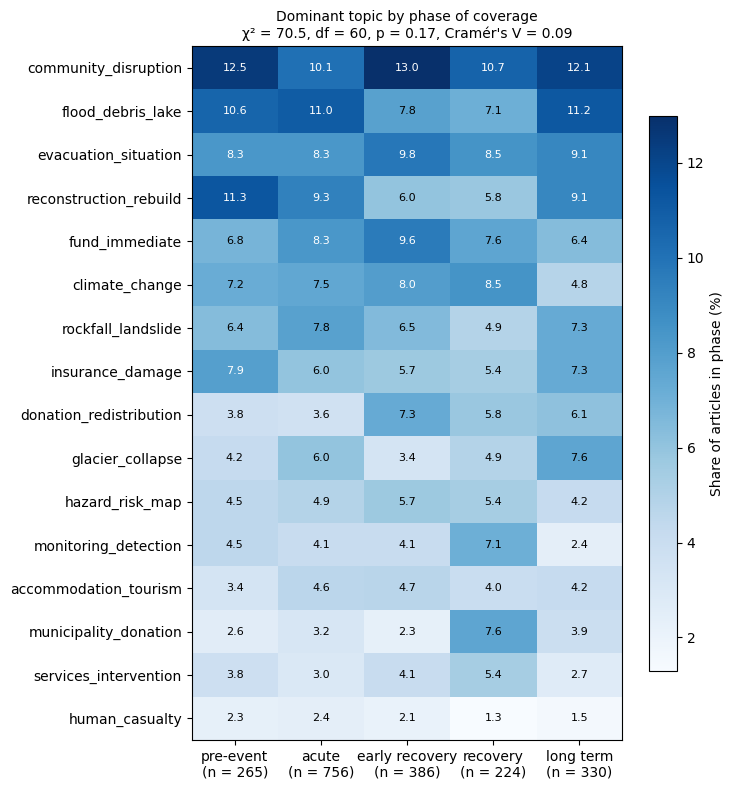

Based on topic weights; slope in percentage points of share per week
                  topic  slope_pp_per_week  ci_low  ci_high      p  p_fdr    trend
         climate_change            -0.0855 -0.1609  -0.0101 0.0277 0.4430 no trend
         human_casualty            -0.0553 -0.1138   0.0032 0.0629 0.4891 no trend
         fund_immediate            -0.0436 -0.1576   0.0705 0.4399 0.9773 no trend
  services_intervention            -0.0209 -0.1154   0.0735 0.6533 0.9773 no trend
       insurance_damage            -0.0189 -0.1152   0.0774 0.6903 0.9773 no trend
   monitoring_detection            -0.0115 -0.0923   0.0692 0.7713 0.9773 no trend
        hazard_risk_map            -0.0077 -0.0762   0.0608 0.8192 0.9773 no trend
     rockfall_landslide            -0.0013 -0.0912   0.0887 0.9773 0.9773 no trend
       glacier_collapse             0.0022 -0.0935   0.0979 0.9632 0.9773 no trend
 reconstruction_rebuild             0.0037 -0.1139   0.1213 0.9493 0.9773 no trend
      flood_debris

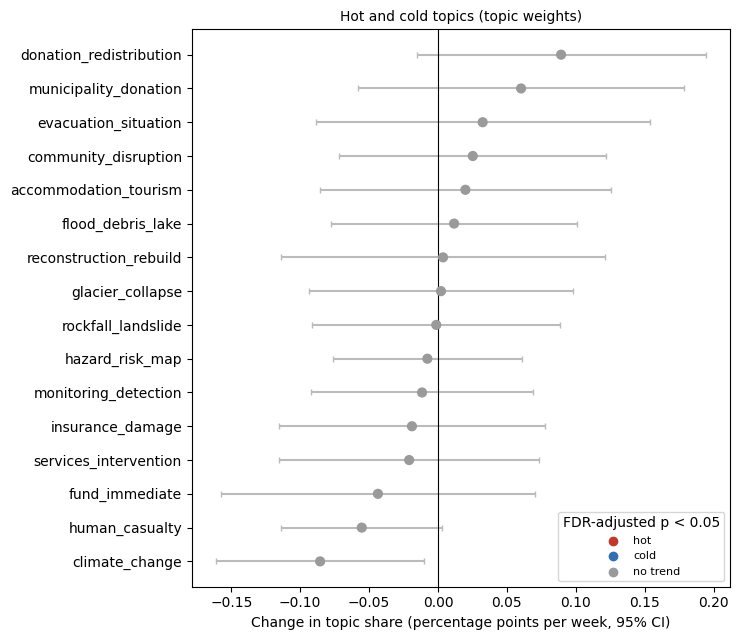

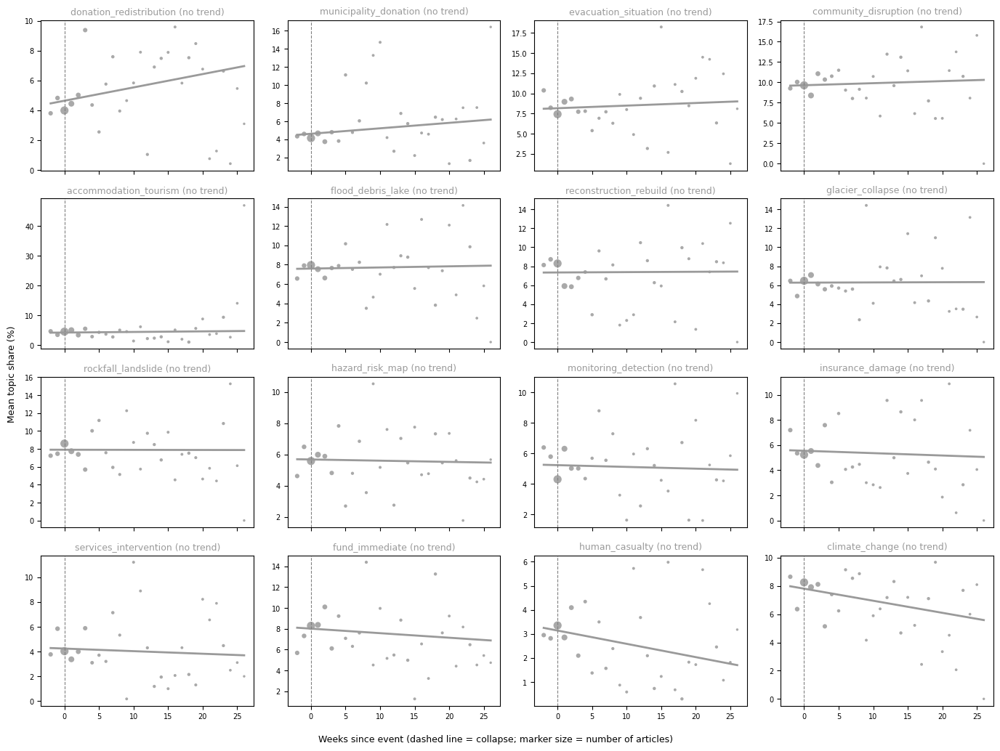

In [ ]:
#Reviewer 3 asked for time trends
# Temporal analysis for the reviewer's "time" comment
# Uses: tsne_df (Dim 1, Dim 2, Topic, Topic Label, week, day), nmf_model, dtm
# Acute: 16 May to 10 June 2025
# Early recovery: 10 June to 10 July 2025
# Recovery: 10 July to 01 September 2025
# Long term: 1 September to 31 December 2025

# %% A. Setup
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from scipy.stats import chi2_contingency

EVENT_DATE = pd.Timestamp("2025-05-28")
PHASES = ["pre-event", "acute", "early recovery", "recovery", "long term"]
BINS = pd.to_datetime(["2025-05-10",   # start of observation window
                       "2025-05-28",   # collapse: acute phase begins
                       "2025-06-09",
                       "2025-06-30",
                       "2025-08-18",
                       "2026-01-01"])  # after end of observation window
EXCLUDED = [4, 14]   # boilerplate components

tsne_df["day"] = pd.to_datetime(tsne_df["day"])
tsne_df["phase"] = pd.cut(tsne_df["day"], bins=BINS, right=False, labels=PHASES)
topic_names = (tsne_df.drop_duplicates("Topic")
               .set_index("Topic")["Topic Label"].to_dict())

# Topic weights for the 1,961 retained articles, checked against tsne_df
W_all = nmf_model.transform(dtm)
W_kept = W_all[~np.isin(W_all.argmax(axis=1), EXCLUDED)]
aligned = (len(W_kept) == len(tsne_df) and
           (W_kept.argmax(axis=1) == tsne_df["Topic"].to_numpy()).all())

keep_idx = [i for i in range(W_all.shape[1]) if i not in EXCLUDED]
if aligned:
    Wk = pd.DataFrame(W_kept[:, keep_idx], index=tsne_df.index,
                      columns=[topic_names.get(i, f"topic_{i}") for i in keep_idx])
    props = Wk.div(Wk.sum(axis=1), axis=0)          # topic proportions per article
    SOURCE = "topic weights"
else:
    # Fallback if rows cannot be matched: 1 for the dominant topic, 0 otherwise
    props = pd.get_dummies(tsne_df["Topic Label"]).astype(float)
    SOURCE = "dominant topic"
print(f"Rows aligned: {aligned}. Hot/cold analysis will use {SOURCE}.")


# %% B. Topic composition by phase: table, test and heatmap
counts = pd.crosstab(tsne_df["Topic Label"], tsne_df["phase"])
shares = (pd.crosstab(tsne_df["Topic Label"], tsne_df["phase"], normalize="columns") * 100).round(1)

chi2, p, dof, expected = chi2_contingency(counts)
cramers_v = np.sqrt(chi2 / (counts.values.sum() * (min(counts.shape) - 1)))
print(f"chi2 = {chi2:.1f}, df = {dof}, p = {p:.3g}, Cramér's V = {cramers_v:.2f}, "
      f"cells with expected < 5: {(expected < 5).mean():.0%}")

shares.to_csv(figure_path + "topic_shares_by_phase.csv")
counts.to_csv(figure_path + "topic_counts_by_phase.csv")

order = shares.mean(axis=1).sort_values(ascending=False).index
S = shares.loc[order]
fig, ax = plt.subplots(figsize=(7.5, 8))
im = ax.imshow(S.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(PHASES)))
ax.set_xticklabels([f"{ph}\n(n = {n})" for ph, n in counts.sum().items()])
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order)
for i in range(S.shape[0]):
    for j in range(S.shape[1]):
        val = S.values[i, j]
        ax.text(j, i, f"{val:.1f}", ha="center", va="center", fontsize=8,
                color="white" if val > 0.6 * S.values.max() else "black")
fig.colorbar(im, ax=ax, label="Share of articles in phase (%)", shrink=0.8)
ax.set_title("Dominant topic by phase of coverage\n"
             f"χ² = {chi2:.1f}, df = {dof}, p = {p:.2f}, Cramér's V = {cramers_v:.2f}",
             fontsize=10)
plt.tight_layout()
plt.savefig(figure_path+"topic_shares_by_phase_heatmap.png", dpi=300)
plt.savefig(figure_path+"topic_shares_by_phase_heatmap.svg", dpi='figure')
plt.show()


# %% C. Hot and cold topics (Griffiths & Steyvers 2004)
week = ((tsne_df["day"] - EVENT_DATE).dt.days // 7).rename("weeks_since_event")
weekly = props.groupby(week).mean()                      # mean topic share per week
n_week = week.value_counts().reindex(weekly.index)       # articles per week
x = weekly.index.to_numpy(dtype=float)
X = sm.add_constant(x)

rows, fits = [], {}
for topic in weekly.columns:
    fit = sm.WLS(weekly[topic].to_numpy(), X, weights=n_week.to_numpy()).fit()
    lo, hi = fit.conf_int()[1]
    fits[topic] = fit
    rows.append({"topic": topic, "slope_pp_per_week": fit.params[1] * 100,
                 "ci_low": lo * 100, "ci_high": hi * 100, "p": fit.pvalues[1]})

trend = pd.DataFrame(rows)
trend["p_fdr"] = multipletests(trend["p"], method="fdr_bh")[1]
trend["trend"] = np.select(
    [(trend.p_fdr < 0.05) & (trend.slope_pp_per_week > 0),
     (trend.p_fdr < 0.05) & (trend.slope_pp_per_week < 0)],
    ["hot", "cold"], default="no trend")
trend = trend.sort_values("slope_pp_per_week").reset_index(drop=True)
trend.round(4).to_csv("hot_cold_topics.csv", index=False)
print(f"Based on {SOURCE}; slope in percentage points of share per week")
print(trend.round(4).to_string(index=False))

COLORS = {"hot": "#c0392b", "cold": "#2e6fb5", "no trend": "#9a9a9a"}


# %% D. Plot: trend per topic with 95% confidence intervals
fig, ax = plt.subplots(figsize=(7.5, 6.5))
y = np.arange(len(trend))
ax.errorbar(trend["slope_pp_per_week"], y,
            xerr=[trend["slope_pp_per_week"] - trend["ci_low"],
                  trend["ci_high"] - trend["slope_pp_per_week"]],
            fmt="none", ecolor="#bbbbbb", elinewidth=1.5, capsize=2)
ax.scatter(trend["slope_pp_per_week"], y, c=trend["trend"].map(COLORS), s=40, zorder=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(y)
ax.set_yticklabels(trend["topic"])
ax.set_xlabel("Change in topic share (percentage points per week, 95% CI)")
for lab, col in COLORS.items():
    ax.scatter([], [], c=col, label=lab)
ax.legend(title="FDR-adjusted p < 0.05", fontsize=8, loc="lower right")
ax.set_title(f"Hot and cold topics ({SOURCE})", fontsize=10)
plt.tight_layout()
plt.savefig(figure_path + "hot_cold_topics_slopes.png", dpi=300)
plt.savefig(figure_path + "hot_cold_topics_slopes.svg", dpi='figure')
plt.show()


# %% E. Plot: weekly share of every topic with fitted trend (small multiples)
topics = trend.sort_values("slope_pp_per_week", ascending=False)["topic"].tolist()
ncols = 4
nrows = int(np.ceil(len(topics) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, 2.6 * nrows), sharex=True)
sizes = 6 + 60 * n_week.to_numpy() / n_week.max()        # marker size = n articles
lab = trend.set_index("topic")["trend"]
x_line = np.linspace(x.min(), x.max(), 50)

for ax, topic in zip(axes.flat, topics):
    ax.scatter(x, weekly[topic] * 100, s=sizes, alpha=0.5, color="#555555", lw=0)
    ax.plot(x_line, fits[topic].predict(sm.add_constant(x_line)) * 100,
            color=COLORS[lab[topic]], lw=2)
    ax.axvline(0, ls="--", color="grey", lw=0.8)
    ax.set_title(f"{topic} ({lab[topic]})", fontsize=9, color=COLORS[lab[topic]])
    ax.tick_params(labelsize=7)
for ax in axes.flat[len(topics):]:
    ax.axis("off")
fig.supxlabel("Weeks since event (dashed line = collapse; marker size = number of articles)", fontsize=9)
fig.supylabel("Mean topic share (%)", fontsize=9)
plt.tight_layout()
plt.savefig(figure_path + "hot_cold_topics_weekly.png", dpi=300)
plt.savefig(figure_path + "hot_cold_topics_weekly.svg", dpi='figure')
plt.show()

In [ ]:
tsne_df.to_csv(file_path +'tsne_df_output_2.csv')

In [ ]:
# Select the colors for each topic (ensure the order matches the topic mapping)
colors = sns.color_palette("tab20", len(topic_mapping))

# Create a dictionary to map topic labels to specific colors
color_mapping = {label: colors[i] for i, label in enumerate(topic_mapping.values())}

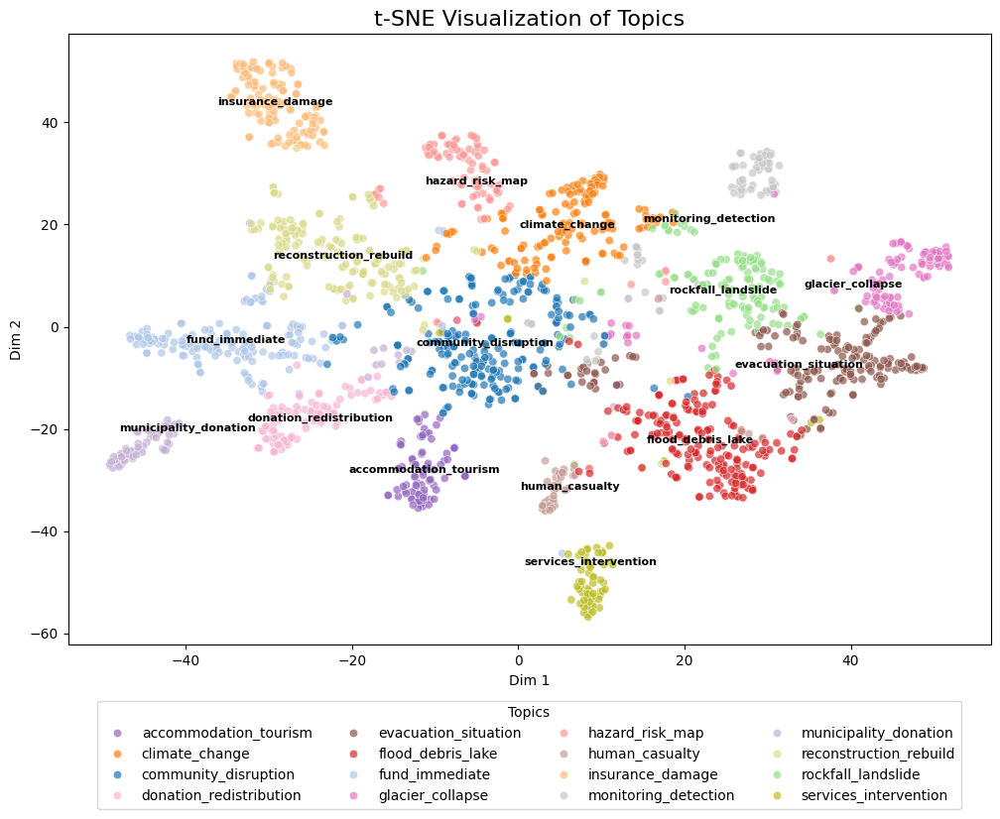

In [ ]:
plt.figure(figsize=(12, 8))
scatter = sns.scatterplot(data=tsne_df, x='Dim 1', y='Dim 2', hue='Topic Label', palette=color_mapping, alpha=0.7)

# Draw straight lines indicating the labels
for topic in valid_topics:
    center = tsne_df[tsne_df['Topic'] == topic][['Dim 1', 'Dim 2']].mean()  # Calculate center
    plt.text(center['Dim 1'], center['Dim 2'], topic_mapping[topic],
             horizontalalignment='center', verticalalignment='center', fontsize=8, weight='bold')

plt.title('t-SNE Visualization of Topics', fontsize=16)

# Sorting the legend in alphabetical order based on the unique Topic Labels
handles, labels = scatter.get_legend_handles_labels()
sorted_indices = sorted(range(len(labels)), key=lambda i: labels[i])
handles = [handles[i] for i in sorted_indices]
labels = [labels[i] for i in sorted_indices]

# Create the legend with sorted labels
plt.legend(handles, labels, title='Topics', loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=4)

# Save the figure
plt.savefig(figure_path+'topic_modelling_tse_2.png', format='png', dpi=300,
            bbox_inches='tight', pad_inches=0.2,
            facecolor='auto', edgecolor='auto',
            backend=None)

plt.savefig(figure_path+'topic_modelling_tse_2.svg', format='svg', dpi='figure',
            bbox_inches='tight', pad_inches=0.2,
            facecolor='auto', edgecolor='auto',
            backend=None)

plt.show()

In [ ]:
npr['date']

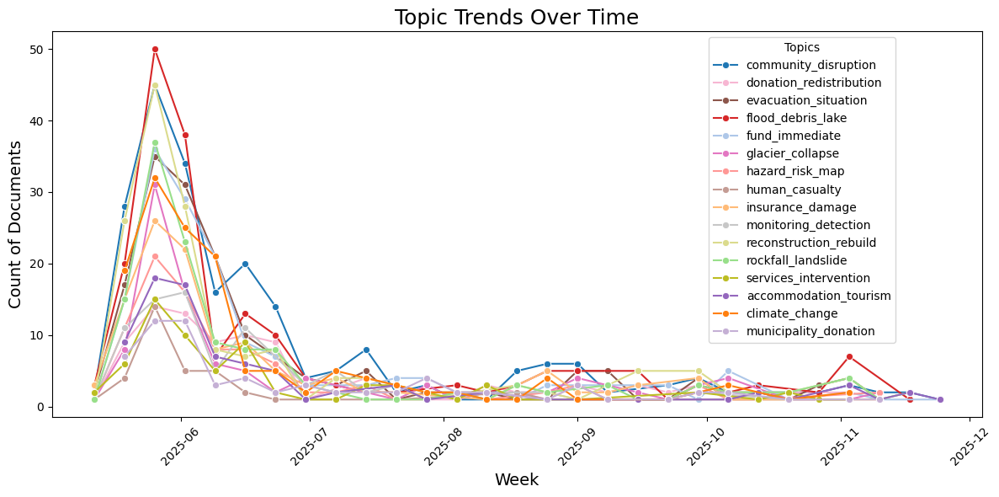

In [ ]:
# Aggregating the data to count occurrences of each topic label per year
topic_trends = tsne_df.groupby(['week', 'Topic Label']).size().reset_index(name='count')
topic_trends_select = topic_trends[topic_trends["week"].dt.month.between(5, 12)]

# Generate a color palette based on the number of unique topic labels
unique_labels = topic_trends_select['Topic Label'].unique()
num_labels = len(unique_labels)
palette = sns.color_palette("tab20", num_labels)  # Create a distinct color palette

# Now we can plot the trends over time
plt.figure(figsize=(12, 6))

# Using seaborn's lineplot to show the trends with topic labels as hue
sns.lineplot(data=topic_trends_select, x='week', y='count', hue='Topic Label', palette=color_mapping, marker='o')

plt.title('Topic Trends Over Time', fontsize=18)
plt.xlabel('Week', fontsize=14)
plt.ylabel('Count of Documents', fontsize=14)
plt.legend(title='Topics', bbox_to_anchor=(0.7, 1), loc='upper left')
plt.xticks(rotation=45)  # Optional: Rotate x-axis labels for better readability
plt.tight_layout()
plt.savefig(figure_path+'topic_trends.png', dpi=300,
       bbox_inches='tight', pad_inches=0.2,
        facecolor='auto', edgecolor='auto',
       backend=None)
plt.savefig(figure_path+'topic_trends.svg', dpi='figure',
       bbox_inches='tight', pad_inches=0.2,
        facecolor='auto', edgecolor='auto',
       backend=None)

In [ ]:
#topic_trends_select = topic_trends[topic_trends["week"].dt.month.between(4, 5)]

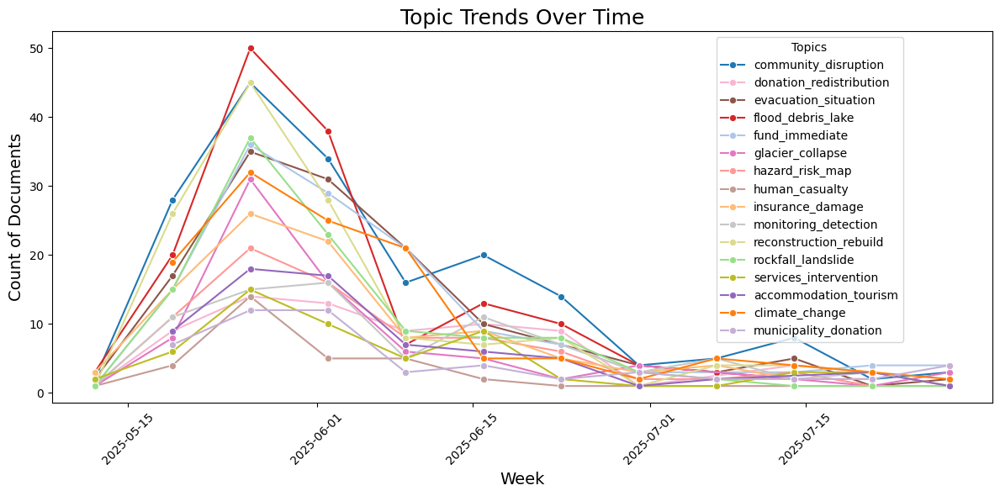

In [ ]:
topic_daily = tsne_df.groupby(['day', 'Topic Label']).size().reset_index(name='count')
topic_daily
topic_daily.set_index('day', inplace=True)
topic_daily_select = topic_daily[topic_daily.index.month == 5]

# Aggregating the data to count occurrences of each topic label per year
topic_trends = tsne_df.groupby(['week', 'Topic Label']).size().reset_index(name='count')
topic_trends_select = topic_trends[topic_trends["week"].dt.month.between(5, 7)]

# Generate a color palette based on the number of unique topic labels
unique_labels = topic_trends_select['Topic Label'].unique()
num_labels = len(unique_labels)
palette = sns.color_palette("tab20", num_labels)  # Create a distinct color palette

# Now we can plot the trends over time
plt.figure(figsize=(12, 6))

# Using seaborn's lineplot to show the trends with topic labels as hue
sns.lineplot(data=topic_trends_select, x='week', y='count', hue='Topic Label', palette=color_mapping, marker='o')

plt.title('Topic Trends Over Time', fontsize=18)
plt.xlabel('Week', fontsize=14)
plt.ylabel('Count of Documents', fontsize=14)
plt.legend(title='Topics', bbox_to_anchor=(0.7, 1), loc='upper left')
plt.xticks(rotation=45)  # Optional: Rotate x-axis labels for better readability
plt.tight_layout()
#plt.savefig('../../Data/ClimateEducation/Figures_092024/Topic_trends.eps', format ='eps', dpi='figure',
#        bbox_inches='tight', pad_inches=0.2,
#        facecolor='auto', edgecolor='auto',
#        backend=None)

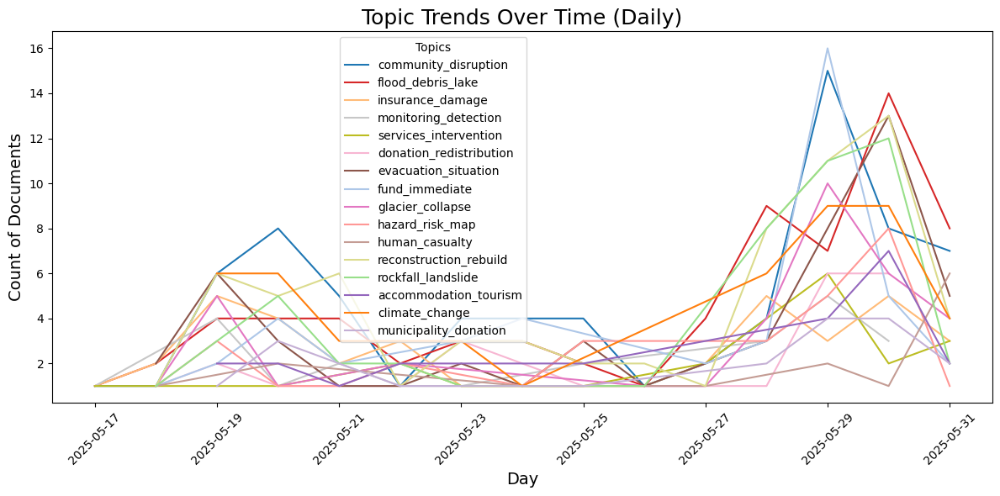

In [ ]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=topic_daily_select.sort_index(),
    x=topic_daily_select.index,   # datetime index = day
    y='count',
    hue='Topic Label',
    palette=color_mapping,         # your existing mapping
)

plt.title('Topic Trends Over Time (Daily)', fontsize=18)
plt.xlabel('Day', fontsize=14)
plt.ylabel('Count of Documents', fontsize=14)
plt.legend(title='Topics', bbox_to_anchor=(0.3, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# Assuming topic_trends is already defined as your DataFrame
# Group by 'Topic Label' and sum occurrences
topic_sums = topic_trends.groupby('Topic Label')['count'].sum().reset_index()

# Calculate the percentage of each topic
total_count = topic_sums['count'].sum()
topic_sums['percentage'] = (topic_sums['count'] / total_count) * 100

print(topic_sums)
print(topic_sums['percentage'].sort_values(ascending=True))

                Topic Label  count  percentage
0     accommodation_tourism     85    4.334523
1            climate_change    142    7.241203
2      community_disruption    223   11.371749
3   donation_redistribution     98    4.997450
4      evacuation_situation    172    8.771035
5         flood_debris_lake    194    9.892912
6            fund_immediate    156    7.955125
7          glacier_collapse    105    5.354411
8           hazard_risk_map     97    4.946456
9            human_casualty     40    2.039776
10         insurance_damage    124    6.323304
11     monitoring_detection     83    4.232534
12    municipality_donation     70    3.569607
13   reconstruction_rebuild    166    8.465069
14       rockfall_landslide    136    6.935237
15    services_intervention     70    3.569607
9      2.039776
12     3.569607
15     3.569607
11     4.232534
0      4.334523
8      4.946456
3      4.997450
7      5.354411
10     6.323304
14     6.935237
1      7.241203
6      7.955125
13     8.

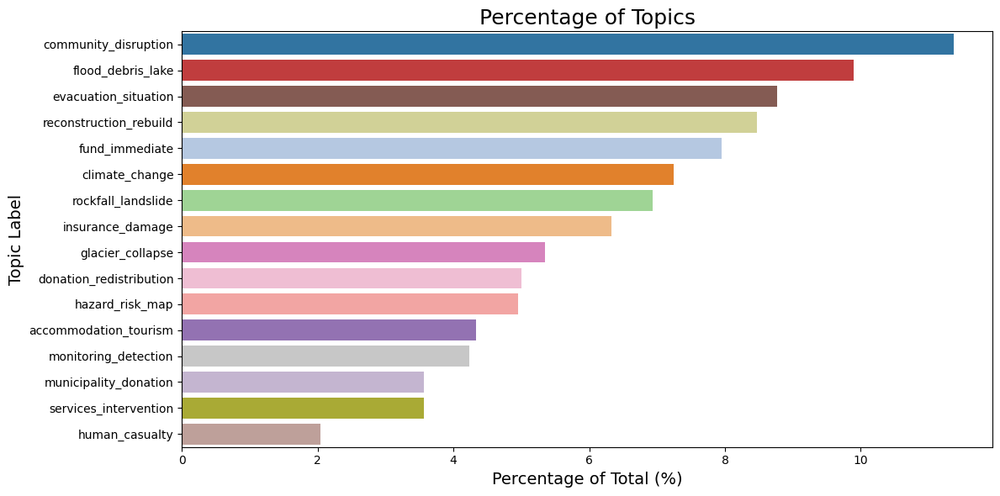

In [ ]:
# Set the figure size
plt.figure(figsize=(12, 6))

topic_sums_sorted = topic_sums.sort_values(by='percentage', ascending=False)

# Create a bar plot to show the percentage
sns.barplot(data=topic_sums_sorted, x='percentage', y='Topic Label',palette=color_mapping)
# Adding titles and labels
plt.title('Percentage of Topics', fontsize=18)
plt.xlabel('Percentage of Total (%)', fontsize=14)
plt.ylabel('Topic Label', fontsize=14)

# Show the plot
plt.tight_layout()
plt.savefig(figure_path+'topic_modelling_percentage.png', dpi=300,
        bbox_inches='tight', pad_inches=0.2,
        facecolor='auto', edgecolor='auto',
        backend=None)

plt.savefig(figure_path+'topic_modelling_percentage.svg', dpi='figure',
        bbox_inches='tight', pad_inches=0.2,
        facecolor='auto', edgecolor='auto',
        backend=None)

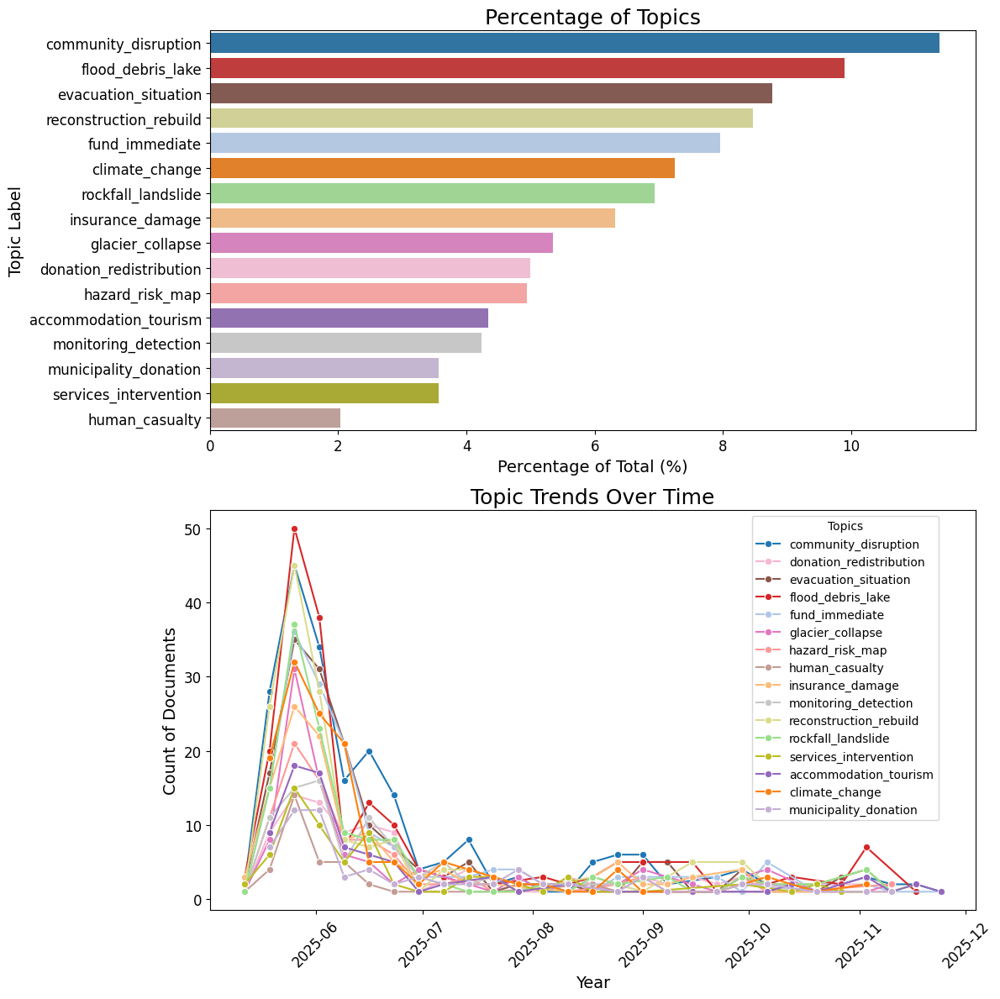

In [ ]:
# Create a figure with two subplots: one for the bar plot and one for the line plot
fig, ax1 = plt.subplots(2, 1, figsize=(12, 12))  # 2 rows, 1 column

# **Bar Plot** (First subplot)
#topic_sums_sorted = topic_sums.sort_values(by='percentage', ascending=False)
sns.barplot(data=topic_sums_sorted, x='percentage', y='Topic Label', palette=color_mapping, ax=ax1[0])
ax1[0].set_title('Percentage of Topics', fontsize=18)
ax1[0].set_xlabel('Percentage of Total (%)', fontsize=14)
ax1[0].set_ylabel('Topic Label', fontsize=14)
ax1[0].tick_params(axis='y', labelsize=12)
ax1[0].tick_params(axis='x', labelsize=12)

# **Line Plot** (Second subplot)
#topic_trends = tsne_df.groupby(['year', 'Topic Label']).size().reset_index(name='count')
#unique_labels = topic_trends['Topic Label'].unique()
#num_labels = len(unique_labels)
#color_mapping = sns.color_palette("tab20", num_labels)  # Create a distinct color palette

sns.lineplot(data=topic_trends, x='week', y='count', hue='Topic Label', palette=color_mapping, marker='o', ax=ax1[1])
ax1[1].set_title('Topic Trends Over Time', fontsize=18)
ax1[1].set_xlabel('Year', fontsize=14)
ax1[1].set_ylabel('Count of Documents', fontsize=14)
ax1[1].legend(title='Topics', bbox_to_anchor=(0.7, 1), loc='upper left')
ax1[1].tick_params(axis='x', rotation=45)  # Rotate x-axis labels for better readability
ax1[1].tick_params(axis='y', labelsize=12)
ax1[1].tick_params(axis='x', labelsize=12)

# Adjust layout to prevent overlap
plt.tight_layout()

# Save the combined figure
plt.savefig(figure_path+'topic_modelling_percentage_trends.png',
            format='svg', dpi=300,
            bbox_inches='tight', pad_inches=0.2,
            facecolor='auto', edgecolor='auto')

plt.savefig(figure_path+'topic_modelling_percentage.svg', dpi='figure',
        bbox_inches='tight', pad_inches=0.2,
        facecolor='auto', edgecolor='auto',
        backend=None)

# Show the combined figure
plt.show()

In [ ]:
# Generate a color palette
#unique_labels = topic_sums['Topic Label'].unique()
#palette = sns.color_palette("tab20", len(unique_labels))  # Use the same palette to maintain consistency

# Create a mapping of topic labels to colors
#color_mapping = {label: palette[i] for i, label in enumerate(unique_labels)}

In [ ]:
npr_topics

,index,Unnamed: 0,id,pubtime,medium_code,medium_name,rubric,regional,doctype,doctype_description,...,topic_8,topic_9,topic_10,topic_11,topic_12,topic_13,topic_14,topic_15,topic_16,topic_17
0,0,0,58309478,2025-09-21 15:14:32+02,NNHEU,24heures.ch,Valais,NaN,WWE,Online medium,...,0.000000,0.000000,0.000984,0.005216,0.000000,0.177599,0.000000,0.009880,0.000000,0.055529
1,1,1,57159417,2025-06-06 00:00:00+02,NZZ,Neue Zürcher Zeitung,Wirtschaft,NaN,PND,National daily newspaper,...,0.000000,0.020060,0.001917,0.000000,0.015579,0.013085,0.001882,0.000000,0.000000,0.108504
2,2,2,57176265,2025-06-07 13:45:28+02,NZZO,nzz.ch,visuals,NaN,WWE,Online medium,...,0.000000,0.000452,0.000000,0.009810,0.061506,0.000000,0.003314,0.000000,0.000000,0.000000
3,3,3,57097109,2025-05-28 17:55:51+02,NNBU,derbund.ch,Schweiz,NaN,WWE,Online medium,...,0.000000,0.000000,0.000000,0.000000,0.007907,0.000000,0.000000,0.000000,0.020637,0.000000
4,4,4,57167960,2025-06-06 17:21:50+02,SWII,swissinfo.ch,Various,NaN,WWE,Online medium,...,0.013007,0.000000,0.067708,0.000000,0.000000,0.000000,0.008894,0.000000,0.000000,0.015451
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2047,2089,2138,57125074,2025-06-03 00:00:00+02,TPS,Le Temps,Suisse,NaN,PND,National daily newspaper,...,0.000000,0.000000,0.018827,0.118385,0.000000,0.000000,0.019497,0.022340,0.000571,0.001463
2048,2090,2139,57825702,2025-08-14 00:00:00+02,WOZ,Die Wochenzeitung,Schweiz,NaN,PJO,Regional weekly newspaper,...,0.018271,0.009676,0.000000,0.000000,0.106131,0.000000,0.000000,0.005620,0.000000,0.034276
2049,2091,2140,57345888,2025-06-25 00:00:00+02,NZZ,Neue Zürcher Zeitung,Schweiz,NaN,PND,National daily newspaper,...,0.000000,0.000000,0.020919,0.000000,0.000000,0.000994,0.005481,0.002748,0.000000,0.056369
2050,2092,2141,58452096,2025-10-06 00:00:00+02,WZ,Wiler Zeitung,Lesernotizen,NaN,PRD,Regional daily newspaper,...,0.016515,0.002189,0.000000,0.000000,0.000000,0.000000,0.000000,0.005736,0.003006,0.000000


In [ ]:
npr_topics['Topic'] = topic_results.argmax(axis=1)
npr_topics['Topic Label'] = npr_topics['Topic'].map(topic_mapping)

In [ ]:
npr_topics

,index,Unnamed: 0,id,pubtime,medium_code,medium_name,rubric,regional,doctype,doctype_description,...,topic_10,topic_11,topic_12,topic_13,topic_14,topic_15,topic_16,topic_17,Topic,Topic Label
0,0,0,58309478,2025-09-21 15:14:32+02,NNHEU,24heures.ch,Valais,NaN,WWE,Online medium,...,0.000984,0.005216,0.000000,0.177599,0.000000,0.009880,0.000000,0.055529,13,donation_redistribution
1,1,1,57159417,2025-06-06 00:00:00+02,NZZ,Neue Zürcher Zeitung,Wirtschaft,NaN,PND,National daily newspaper,...,0.001917,0.000000,0.015579,0.013085,0.001882,0.000000,0.000000,0.108504,17,reconstruction_rebuild
2,2,2,57176265,2025-06-07 13:45:28+02,NZZO,nzz.ch,visuals,NaN,WWE,Online medium,...,0.000000,0.009810,0.061506,0.000000,0.003314,0.000000,0.000000,0.000000,5,rockfall_landslide
3,3,3,57097109,2025-05-28 17:55:51+02,NNBU,derbund.ch,Schweiz,NaN,WWE,Online medium,...,0.000000,0.000000,0.007907,0.000000,0.000000,0.000000,0.020637,0.000000,6,flood_debris_lake
4,4,4,57167960,2025-06-06 17:21:50+02,SWII,swissinfo.ch,Various,NaN,WWE,Online medium,...,0.067708,0.000000,0.000000,0.000000,0.008894,0.000000,0.000000,0.015451,4,translation_deepl
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2047,2089,2138,57125074,2025-06-03 00:00:00+02,TPS,Le Temps,Suisse,NaN,PND,National daily newspaper,...,0.018827,0.118385,0.000000,0.000000,0.019497,0.022340,0.000571,0.001463,11,human_casualty
2048,2090,2139,57825702,2025-08-14 00:00:00+02,WOZ,Die Wochenzeitung,Schweiz,NaN,PJO,Regional weekly newspaper,...,0.000000,0.000000,0.106131,0.000000,0.000000,0.005620,0.000000,0.034276,12,glacier_collapse
2049,2091,2140,57345888,2025-06-25 00:00:00+02,NZZ,Neue Zürcher Zeitung,Schweiz,NaN,PND,National daily newspaper,...,0.020919,0.000000,0.000000,0.000994,0.005481,0.002748,0.000000,0.056369,0,community_disruption
2050,2092,2141,58452096,2025-10-06 00:00:00+02,WZ,Wiler Zeitung,Lesernotizen,NaN,PRD,Regional daily newspaper,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.005736,0.003006,0.000000,0,community_disruption


In [ ]:
# build the actual column rename dict: 'topic_0' -> 'community_disruption', etc.
rename_cols = {f"topic_{k}": v for k, v in topic_mapping.items()}

# rename (in place or assign back)
npr_topics = npr_topics.rename(columns=rename_cols)

In [ ]:
npr_topics

,index,Unnamed: 0,id,pubtime,medium_code,medium_name,rubric,regional,doctype,doctype_description,...,evacuation_situation,human_casualty,glacier_collapse,donation_redistribution,online_collection_campaign,monitoring_detection,services_intervention,reconstruction_rebuild,Topic,Topic Label
0,0,0,58309478,2025-09-21 15:14:32+02,NNHEU,24heures.ch,Valais,NaN,WWE,Online medium,...,0.000984,0.005216,0.000000,0.177599,0.000000,0.009880,0.000000,0.055529,13,donation_redistribution
1,1,1,57159417,2025-06-06 00:00:00+02,NZZ,Neue Zürcher Zeitung,Wirtschaft,NaN,PND,National daily newspaper,...,0.001917,0.000000,0.015579,0.013085,0.001882,0.000000,0.000000,0.108504,17,reconstruction_rebuild
2,2,2,57176265,2025-06-07 13:45:28+02,NZZO,nzz.ch,visuals,NaN,WWE,Online medium,...,0.000000,0.009810,0.061506,0.000000,0.003314,0.000000,0.000000,0.000000,5,rockfall_landslide
3,3,3,57097109,2025-05-28 17:55:51+02,NNBU,derbund.ch,Schweiz,NaN,WWE,Online medium,...,0.000000,0.000000,0.007907,0.000000,0.000000,0.000000,0.020637,0.000000,6,flood_debris_lake
4,4,4,57167960,2025-06-06 17:21:50+02,SWII,swissinfo.ch,Various,NaN,WWE,Online medium,...,0.067708,0.000000,0.000000,0.000000,0.008894,0.000000,0.000000,0.015451,4,translation_deepl
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2047,2089,2138,57125074,2025-06-03 00:00:00+02,TPS,Le Temps,Suisse,NaN,PND,National daily newspaper,...,0.018827,0.118385,0.000000,0.000000,0.019497,0.022340,0.000571,0.001463,11,human_casualty
2048,2090,2139,57825702,2025-08-14 00:00:00+02,WOZ,Die Wochenzeitung,Schweiz,NaN,PJO,Regional weekly newspaper,...,0.000000,0.000000,0.106131,0.000000,0.000000,0.005620,0.000000,0.034276,12,glacier_collapse
2049,2091,2140,57345888,2025-06-25 00:00:00+02,NZZ,Neue Zürcher Zeitung,Schweiz,NaN,PND,National daily newspaper,...,0.020919,0.000000,0.000000,0.000994,0.005481,0.002748,0.000000,0.056369,0,community_disruption
2050,2092,2141,58452096,2025-10-06 00:00:00+02,WZ,Wiler Zeitung,Lesernotizen,NaN,PRD,Regional daily newspaper,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.005736,0.003006,0.000000,0,community_disruption


In [ ]:
#npr_topics["Topic"].value_counts(normalize=True)*100

In [ ]:
#npr_topics["Topic"].value_counts()

In [ ]:
npr_topics[npr_topics['Topic'].isin(allowed_topics)]

,index,Unnamed: 0,id,pubtime,medium_code,medium_name,rubric,regional,doctype,doctype_description,...,evacuation_situation,human_casualty,glacier_collapse,donation_redistribution,online_collection_campaign,monitoring_detection,services_intervention,reconstruction_rebuild,Topic,Topic Label
0,0,0,58309478,2025-09-21 15:14:32+02,NNHEU,24heures.ch,Valais,NaN,WWE,Online medium,...,0.000984,0.005216,0.000000,0.177599,0.000000,0.009880,0.000000,0.055529,13,donation_redistribution
1,1,1,57159417,2025-06-06 00:00:00+02,NZZ,Neue Zürcher Zeitung,Wirtschaft,NaN,PND,National daily newspaper,...,0.001917,0.000000,0.015579,0.013085,0.001882,0.000000,0.000000,0.108504,17,reconstruction_rebuild
2,2,2,57176265,2025-06-07 13:45:28+02,NZZO,nzz.ch,visuals,NaN,WWE,Online medium,...,0.000000,0.009810,0.061506,0.000000,0.003314,0.000000,0.000000,0.000000,5,rockfall_landslide
3,3,3,57097109,2025-05-28 17:55:51+02,NNBU,derbund.ch,Schweiz,NaN,WWE,Online medium,...,0.000000,0.000000,0.007907,0.000000,0.000000,0.000000,0.020637,0.000000,6,flood_debris_lake
5,5,5,57092182,2025-05-30 00:00:00+02,ZWA,20 minuten,BLATTEN,Zürich,PRD,Regional daily newspaper,...,0.005566,0.000000,0.022088,0.000000,0.001617,0.000000,0.001041,0.020509,0,community_disruption
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2047,2089,2138,57125074,2025-06-03 00:00:00+02,TPS,Le Temps,Suisse,NaN,PND,National daily newspaper,...,0.018827,0.118385,0.000000,0.000000,0.019497,0.022340,0.000571,0.001463,11,human_casualty
2048,2090,2139,57825702,2025-08-14 00:00:00+02,WOZ,Die Wochenzeitung,Schweiz,NaN,PJO,Regional weekly newspaper,...,0.000000,0.000000,0.106131,0.000000,0.000000,0.005620,0.000000,0.034276,12,glacier_collapse
2049,2091,2140,57345888,2025-06-25 00:00:00+02,NZZ,Neue Zürcher Zeitung,Schweiz,NaN,PND,National daily newspaper,...,0.020919,0.000000,0.000000,0.000994,0.005481,0.002748,0.000000,0.056369,0,community_disruption
2050,2092,2141,58452096,2025-10-06 00:00:00+02,WZ,Wiler Zeitung,Lesernotizen,NaN,PRD,Regional daily newspaper,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.005736,0.003006,0.000000,0,community_disruption


In [ ]:
topic_counts = npr_topics['Topic'].value_counts(normalize=True)*100
npr_topics_select = npr_topics[npr_topics['Topic'].isin(allowed_topics)]

In [ ]:
#npr_topics.to_csv('../../Data/ClimateEducation/npr_topics.csv')

In [ ]:
import matplotlib.colors as pltc
import matplotlib.ticker as mtick

Text(0.5, 1.0, 'Topic prevalence')

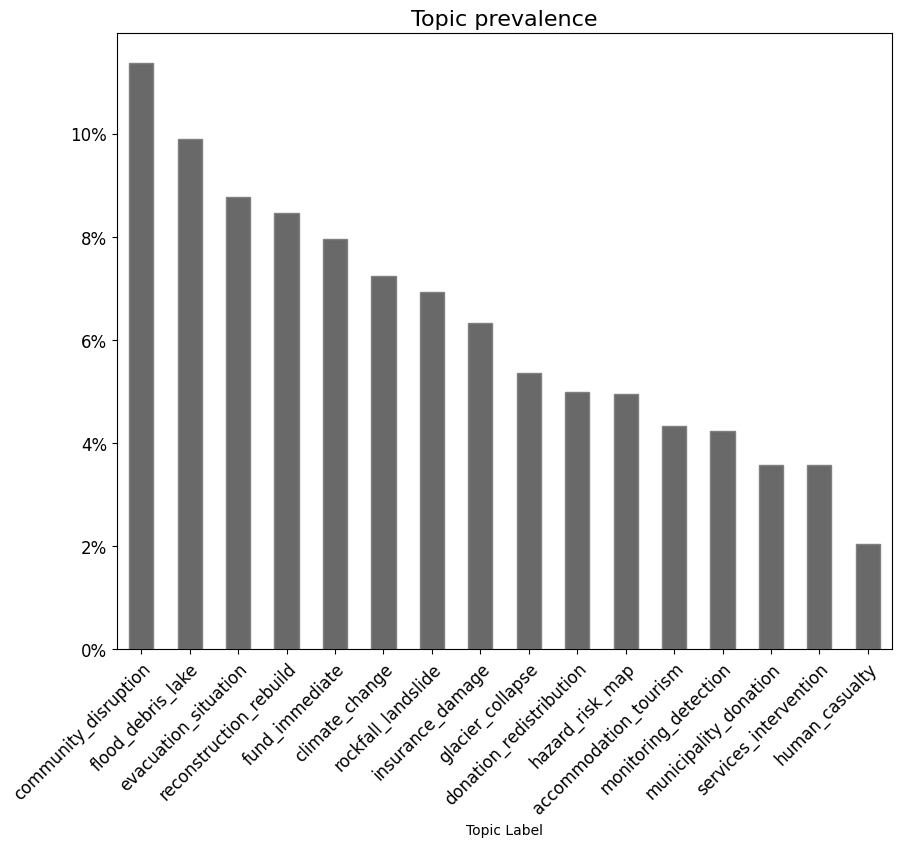

In [ ]:
all_colors = [k for k,v in pltc.cnames.items()]
from random import sample
#import random
#random.seed(22)
#colors = sample(all_colors,npr_2008["Topic Label"].nunique())
#print(colors)
#ax = (npr_2008["Topic Label"].value_counts(normalize=True)*100).plot.bar(figsize = (10,8),color= colors)
ax = (npr_topics_select["Topic Label"].value_counts(normalize=True)*100).plot.bar(figsize = (10,8),color= 'dimgrey',edgecolor = 'grey')
ax.set_xticklabels(ax.get_xticklabels(), rotation = 45, fontsize=12, ha='right', rotation_mode="anchor")
ax.set_yticklabels(ax.get_yticklabels(),fontsize=12)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals = 0))
#ax.set_ylabel("Topic prevalence", fontsize=14)
ax.set_title("Topic prevalence", fontsize=16)
#plt.savefig('../../Data/ClimateEducation/Figures_092024/Paper_topic.eps', format ='eps', dpi='figure',
#        bbox_inches='tight', pad_inches=0.2,
#        facecolor='auto', edgecolor='auto',
#        backend=None)

In [ ]:
npr_topics_select["Topic Label"].value_counts(normalize=True)*100

,proportion
Topic Label,
community_disruption,11.371749
flood_debris_lake,9.892912
evacuation_situation,8.771035
reconstruction_rebuild,8.465069
fund_immediate,7.955125
climate_change,7.241203
rockfall_landslide,6.935237
insurance_damage,6.323304
glacier_collapse,5.354411


In [ ]:
npr_topics_select["Topic"].value_counts(normalize=True).sort_index()

,proportion
Topic,
0,0.113717
1,0.079551
2,0.072412
3,0.063233
5,0.069352
6,0.098929
7,0.049465
8,0.043345
9,0.035696


In [ ]:
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

def corrfunc(x, y, hue = None, ax=None, **kws):
    """Plot the correlation coefficient in the top left hand corner of a plot."""
    r, _ = pearsonr(x, y)
    ax = ax or plt.gca()
    ax.annotate(f'ρ = {r:.2f}', xy=(.1, .9), xycoords=ax.transAxes)

In [ ]:
npr_topics_select.columns

Index(['index', 'Unnamed: 0', 'id', 'pubtime', 'medium_code', 'medium_name',
       'rubric', 'regional', 'doctype', 'doctype_description', 'language',
       'char_count', 'dateline', 'head', 'subhead', 'article_link',
       'content_id', 'content', 'clean_content', 'event', 'sentiment', 'tone',
       'location', 'name', 'strategy', 'stories', 'analysis', 'narratives',
       'topic', 'combined_text', 'source', 'confidence', 'content_en',
       'translation_retry_count', 'det_lang_en', 'hazard_type',
       'strategy_type', 'split_hazard', 'split_strategy',
       'labels_parsed_hazard', 'label_vector_hazard', 'event_llm',
       'strategy_llm', 'clean_content_en', 'abstract_lemmatized',
       'narratives_lemmatized', 'abstract_norm', 'narratives_norm',
       'community_disruption', 'fund_immediate', 'climate_change',
       'insurance_damage', 'translation_deepl', 'rockfall_landslide',
       'flood_debris_lake', 'hazard_risk_map', 'accommodation_tourism',
       'municipality_d

In [ ]:
npr_corr = npr_topics_select[['community_disruption',
          'fund_immediate',
          'climate_change',
          'insurance_damage',
          'rockfall_landslide',
          'flood_debris_lake',
          'hazard_risk_map',
          'accomodation_tourism',
          'municipality_donation',
          'evacuation_situation',
          'human_casualty',
          'glacier_collapse',
          'donation_redistribution',
          'monitoring_detection',
          'services_intervention',
          'reconstruction_rebuild']]

KeyError: "['accomodation_tourism'] not in index"

In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
ax = npr_corr.boxplot()
ax.set_xticklabels(ax.get_xticklabels(), rotation = 45, fontsize=10, ha='right', rotation_mode="anchor")
plt.savefig(figure_path+'box_plots.svg',dpi='figure',
        bbox_inches='tight', pad_inches=0.2,
        facecolor='auto', edgecolor='auto',
        backend=None)

plt.savefig(figure_path+'box_plots.png',dpi='figure',
        bbox_inches='tight', pad_inches=0.2,
        facecolor='auto', edgecolor='auto',
        backend=None)

In [ ]:
ax = sns.boxplot(data=npr_corr)
ax.set_xticklabels(ax.get_xticklabels(), rotation = 45, fontsize=10, ha='right', rotation_mode="anchor")

In [ ]:
npr_corr

,community_disruption,fund_immediate,climate_change,insurance_damage,rockfall_landslide,flood_debris_lake,hazard_risk_map,accomodation_tourism,municipality_donation,evacuation_situation,human_casualty,glacier_collapse,donation_redistribution,monitoring_detection,services_intervention,reconstruction_rebuild
0,0.000000,0.057462,0.009141,0.006430,0.000000,0.000000,0.000000,0.000000,0.000000,0.000984,0.005216,0.000000,0.177599,0.009880,0.000000,0.055529
1,0.008609,0.044070,0.000000,0.080013,0.010671,0.020350,0.000000,0.000000,0.020060,0.001917,0.000000,0.015579,0.013085,0.000000,0.000000,0.108504
2,0.000000,0.000251,0.000000,0.002544,0.098513,0.022115,0.008755,0.000000,0.000452,0.000000,0.009810,0.061506,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.000000,0.000000,0.075349,0.207651,0.000000,0.000000,0.000000,0.000000,0.000000,0.007907,0.000000,0.000000,0.020637,0.000000
5,0.035716,0.003436,0.000000,0.002375,0.008039,0.015610,0.000000,0.000000,0.000000,0.005566,0.000000,0.022088,0.000000,0.000000,0.001041,0.020509
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2047,0.011965,0.000000,0.016657,0.007187,0.000000,0.020947,0.009364,0.000000,0.000000,0.018827,0.118385,0.000000,0.000000,0.022340,0.000571,0.001463
2048,0.021605,0.000969,0.028945,0.000000,0.014852,0.065720,0.011322,0.018271,0.009676,0.000000,0.000000,0.106131,0.000000,0.005620,0.000000,0.034276
2049,0.068853,0.002825,0.000000,0.001617,0.025517,0.013991,0.020662,0.000000,0.000000,0.020919,0.000000,0.000000,0.000994,0.002748,0.000000,0.056369
2050,0.030308,0.000000,0.001869,0.000000,0.001691,0.012647,0.000000,0.016515,0.002189,0.000000,0.000000,0.000000,0.000000,0.005736,0.003006,0.000000


In [ ]:
aa1=npr_corr.corr(method='spearman')
aa1 = aa1.sort_index()

In [ ]:
aa1 = aa1.sort_index(axis =1)

In [ ]:
aa1

,accomodation_tourism,climate_change,community_disruption,donation_solidarity,event_evacuation,flood_debris_lake,fund_immediate,glacier_melting,hazard_map_red_zone,human_casualty,insurance_damage,monitoring_detection,mountain_collapse_landslide,municipality_aid_redistribute,reconstruction_planning
accomodation_tourism,1.000000,-0.017661,0.169593,0.036160,-0.030996,0.005009,-0.060584,-0.035623,-0.042739,0.109317,0.111039,0.081919,-0.034295,0.135190,0.216866
climate_change,-0.017661,1.000000,0.162642,-0.122033,-0.246053,-0.082687,0.045256,0.075792,0.202188,-0.056550,0.126004,0.288718,-0.006697,-0.031535,-0.038543
community_disruption,0.169593,0.162642,1.000000,0.051515,-0.039640,0.077855,-0.025558,-0.005725,0.008885,0.096395,-0.020546,0.020225,-0.020967,0.088209,0.103184
donation_solidarity,0.036160,-0.122033,0.051515,1.000000,-0.081519,-0.002608,0.278560,-0.101261,-0.082988,0.098529,0.165844,-0.046681,-0.129147,0.102911,0.024189
event_evacuation,-0.030996,-0.246053,-0.039640,-0.081519,1.000000,0.205249,-0.140069,0.119054,0.070048,0.098709,-0.182307,-0.017686,0.132904,-0.030195,-0.129408
flood_debris_lake,0.005009,-0.082687,0.077855,-0.002608,0.205249,1.000000,-0.046768,0.186495,0.066068,0.195079,-0.038252,0.065826,0.084873,-0.041957,0.043072
fund_immediate,-0.060584,0.045256,-0.025558,0.278560,-0.140069,-0.046768,1.000000,-0.206177,-0.004723,0.045881,0.219270,-0.027248,-0.163940,0.164711,0.109066
glacier_melting,-0.035623,0.075792,-0.005725,-0.101261,0.119054,0.186495,-0.206177,1.000000,-0.051086,0.013038,-0.076175,-0.016102,0.204843,-0.150199,-0.122594
hazard_map_red_zone,-0.042739,0.202188,0.008885,-0.082988,0.070048,0.066068,-0.004723,-0.051086,1.000000,0.005398,0.112146,0.160301,0.126565,-0.031124,0.024023
human_casualty,0.109317,-0.056550,0.096395,0.098529,0.098709,0.195079,0.045881,0.013038,0.005398,1.000000,0.035365,0.083504,-0.048114,0.010251,0.080615


In [ ]:
import seaborn as sns
fig, ax = plt.subplots(figsize=(12, 10))
mask = np.triu(np.ones_like(aa1))
sns.heatmap(aa1, ax=ax, cmap='YlGnBu',fmt='g', linewidth=1,mask = mask)
ax.set_xticklabels(labels =ax.get_xticklabels(), rotation=45, ha='right', rotation_mode="anchor")
ax.tick_params(axis='both', labelsize=10)
plt.tight_layout()
plt.savefig(figure_path+'topic_modelling_heatmap.png',dpi=300,
       bbox_inches='tight', pad_inches=0.2,
        facecolor='auto', edgecolor='auto',
        backend=None )

plt.savefig(figure_path+'topic_modelling_heatmap.svg',dpi='figure',
       bbox_inches='tight', pad_inches=0.2,
        facecolor='auto', edgecolor='auto',
        backend=None )

In [ ]:
print("Do you want to save the topic modelling datasets?")
x = input()
if x == 'yes':
    npr_topics.to_csv(file_path+'news_all_topics.csv')
    npr_topics_select.to_csv(file_path+'news_selected_topics.csv')
else:
    print('No need to save because answer was: ' + x)

Do you want to save the topic modelling datasets?
yes


In [ ]:
topic_trends

,week,Topic Label,count
0,2025-05-12,accomodation_tourism,2
1,2025-05-12,community_disruption,3
2,2025-05-12,donation_solidarity,2
3,2025-05-12,event_evacuation,2
4,2025-05-12,flood_debris_lake,2
...,...,...,...
326,2025-11-17,mountain_collapse_landslide,2
327,2025-11-17,municipality_aid_redistribute,1
328,2025-11-24,community_disruption,1
329,2025-11-24,event_evacuation,1


# Summarisation

In [ ]:
%%capture
%pip install --upgrade --quiet  langchain-openai tiktoken chromadb langchain langchainhub langchain-classic
%pip install -qU langchain-ollama
%pip install langchain-community
%pip install langchain_google_genai

In [ ]:
from langchain_openai import ChatOpenAI
from langchain_google_genai import ChatGoogleGenerativeAI
import os
from langchain_community.document_loaders import DataFrameLoader
from langchain_classic.chains.summarize import load_summarize_chain
from langchain_community.document_loaders import DataFrameLoader
from re import T

In [ ]:
from langchain_classic.chains.combine_documents.stuff import StuffDocumentsChain
from langchain_classic.chains.llm import LLMChain
from langchain_core.prompts import PromptTemplate
from langchain_classic.chains import MapReduceDocumentsChain, ReduceDocumentsChain
from langchain_text_splitters import CharacterTextSplitter

In [ ]:
os.environ['OPENAI_API_KEY'] = '....'
ChatOpenAI.api_key = os.getenv('OPENAI_API_KEY')
llm = ChatOpenAI(temperature=0, model_name="gpt-5-nano-2025-08-07")
chain = load_summarize_chain(llm, chain_type="stuff")

In [ ]:
#Input google key
from getpass import getpass
google_api_key = getpass("Enter your Google Studio API key: ")
os.environ["GOOLE_KEY"] = google_api_key
print("Google Studio Key key set successfully!")
llm2 = ChatGoogleGenerativeAI(
    model="models/gemini-3.1-pro-preview",
    api_key=google_api_key,  temperature = 0 # uses GOOGLE_API_KEY env var by default
)
chain = load_summarize_chain(llm2, chain_type="stuff")

Enter your Google Studio API key: ··········
Google Studio Key key set successfully!


In [ ]:
npr_topics['narratives'] = npr_topics['narratives'].astype(str)

* Step 1: Stuff

When we use load_summarize_chain with chain_type="stuff", we will use the StuffDocumentsChain.

The chain will take a list of documents, inserts them all into a prompt, and passes that prompt to an LLM.

In [ ]:
# Define prompt
prompt_template = """The following is a set of news narratives about an event which happened in the
Swiss village of Blatten. Write a detailed summary of the main narratives. Provide a bullet point for each narrative.
Do not invent or make up information which is not strictly in the narrative text.
Do not interpret the meaning of the narratives.
"{text}"
SUMMARY:"""
prompt = PromptTemplate.from_template(prompt_template)

# Define LLM chain
llm = ChatOpenAI(temperature=0, model_name="gpt-5-nano-2025-08-07")
llm_chain = LLMChain(llm=llm, prompt=prompt)

# Define StuffDocumentsChain
stuff_chain = StuffDocumentsChain(llm_chain=llm_chain, document_variable_name="text")

docs = loader.load()

In [ ]:
print(stuff_chain.run(docs))

In [ ]:
# Define prompt
prompt_template = """The following is a set of news narratives about an event which happened in a
Swiss village. Write a concise summary of the "main" narratives that emerge. Provide a bullet point for each narrative.
Do not invent or make up information which is not strictly in the narrative text.
Do not interpret the meaning of the narratives.
"{text}"
SUMMARY:"""
prompt = PromptTemplate.from_template(prompt_template)

# Define LLM chain
llm = ChatOpenAI(temperature=0, model_name="gpt-5-nano-2025-08-07")
llm_chain = LLMChain(llm=llm, prompt=prompt)

# Define StuffDocumentsChain
stuff_chain = StuffDocumentsChain(llm_chain=llm_chain, document_variable_name="text")

docs = loader.load()

In [ ]:
print(stuff_chain.run(docs))

- Blatten disaster: an unprecedented glacier-collapse and debris-flow bury the village, triggering ongoing evacuations and long-term safety and reconstruction concerns.

- Climate change and permafrost thaw: repeated references to warming and thawing as drivers of alpine hazards, prompting calls for enhanced monitoring, hazard maps, early-warning systems, and adaptation.

- Rebuilding versus relocation: dominant debate over whether Blatten should be rebuilt at the original site or relocated (e.g., to Weissenried or Eisten), with red-zone constraints and plans for a new village center and phased timelines.

- Multi-level governance and emergency funding: swift federal, cantonal, and local action; use of emergency decrees and potential for a national catastrophe fund; concerns about donation management and funding mechanisms.

- Insurance and finance: rising premiums, treatment of elemental-damage coverage, payouts, and potential use of catastrophe bonds; debates over who pays and how re

In [ ]:
# Define prompt
prompt_template = """The following is a set of news narratives about an event which happened in the
Swiss village of Blatten. Write a detailed summary of the main narratives. Provide a bullet point for each narrative.
Do not invent or make up information which is not strictly in the narrative text.
Do not interpret the meaning of the narratives.
"{text}"
SUMMARY:"""
prompt = PromptTemplate.from_template(prompt_template)

# Define LLM chain
llm_chain = LLMChain(llm=llm2, prompt=prompt)

# Define StuffDocumentsChain
stuff_chain = StuffDocumentsChain(llm_chain=llm_chain, document_variable_name="text")

npr_select = npr_topics[npr_topics['Topic Label']=='climate_change']
loader = DataFrameLoader(npr_select, page_content_column="narratives")

docs = loader.load()

In [ ]:
print(stuff_chain.run(docs))

Here is a detailed summary of the main narratives found in the provided text, categorized by their central themes:

*   **The Link Between Climate Change and Alpine Hazards:** A prominent narrative attributes the disaster in Blatten to climate change, specifically highlighting that global warming, permafrost thaw, and glacier retreat are destabilizing high-mountain regions and increasing the frequency of rockfalls, landslides, and extreme weather. The Alps are framed as an early warning system for broader climate impacts.
*   **Scientific Caution and Complex Attribution:** In contrast to direct attribution, another narrative emphasizes a calm, science-forward assessment. While acknowledging that climate change increases overall risks, scientists and some commentators caution against linking a single event solely to climate change, noting that disasters are natural geological processes that have historical precedents.
*   **The Debate Over Adaptation vs. Abandonment:** A recurring narra

The set up with Gemini3 Pro achieve a superioir result which is also reflected in the evaluation document

In [ ]:
from langchain_classic.chains import MapReduceDocumentsChain, ReduceDocumentsChain
from langchain_text_splitters import CharacterTextSplitter

#llm = ChatOpenAI(temperature=0)

# Map
map_template = """The following is a set of news narratives about an events which happened in the
Swiss village:
{docs}
Based on this list of news narratives, please identify the main themes.
"""
map_prompt = PromptTemplate.from_template(map_template)
map_chain = LLMChain(llm=llm2, prompt=map_prompt)



In [ ]:
# Reduce
reduce_template = """

The following is set of abstracts:
{docs}

Take these themes which are narratives extracted from the news coverage of the disaster in the
village of Blatten in Switzerland and distill them into a final,
consolidated summary of the most important narratives that are covered by the news.
Please do not repeat text.
# Please do not use bullet points to describe the main topics.

"""
reduce_prompt = PromptTemplate.from_template(reduce_template)

In [ ]:
# Run chain
reduce_chain = LLMChain(llm=llm2, prompt=reduce_prompt)

# Takes a list of documents, combines them into a single string, and passes this to an LLMChain
combine_documents_chain = StuffDocumentsChain(
    llm_chain=reduce_chain, document_variable_name="docs"
)

# Combines and iteratively reduces the mapped documents
reduce_documents_chain = ReduceDocumentsChain(
    # This is final chain that is called.
    combine_documents_chain=combine_documents_chain,
    # If documents exceed context for `StuffDocumentsChain`
    collapse_documents_chain=combine_documents_chain,
    # The maximum number of tokens to group documents into.
    token_max=4000,
)

/tmp/ipykernel_4519/3439994846.py:10: LangChainDeprecationWarning: This class is deprecated. Please see the migration guide here for a recommended replacement: https://python.langchain.com/docs/versions/migrating_chains/map_reduce_chain/
  reduce_documents_chain = ReduceDocumentsChain(


In [ ]:
# Combining documents by mapping a chain over them, then combining results
map_reduce_chain = MapReduceDocumentsChain(
    # Map chain
    llm_chain=map_chain,
    # Reduce chain
    reduce_documents_chain=reduce_documents_chain,
    # The variable name in the llm_chain to put the documents in
    document_variable_name="docs",
    # Return the results of the map steps in the output
    return_intermediate_steps=False,
)

text_splitter = CharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=1000, chunk_overlap=0
)
split_docs = text_splitter.split_documents(docs)

/tmp/ipykernel_4519/1243941426.py:2: LangChainDeprecationWarning: This class is deprecated. Please see the migration guide here for a recommended replacement: https://python.langchain.com/docs/versions/migrating_chains/map_reduce_chain/
  map_reduce_chain = MapReduceDocumentsChain(


In [ ]:
run10 = map_reduce_chain.run(split_docs)
print(run10)

KeyboardInterrupt: 